<div style="background: linear-gradient(135deg, #003366 0%, #0055a5 100%); border-radius: 12px; padding: 18px 26px; display: flex; align-items: center; gap: 24px; box-shadow: 0 4px 12px rgba(0,0,0,0.2);">
    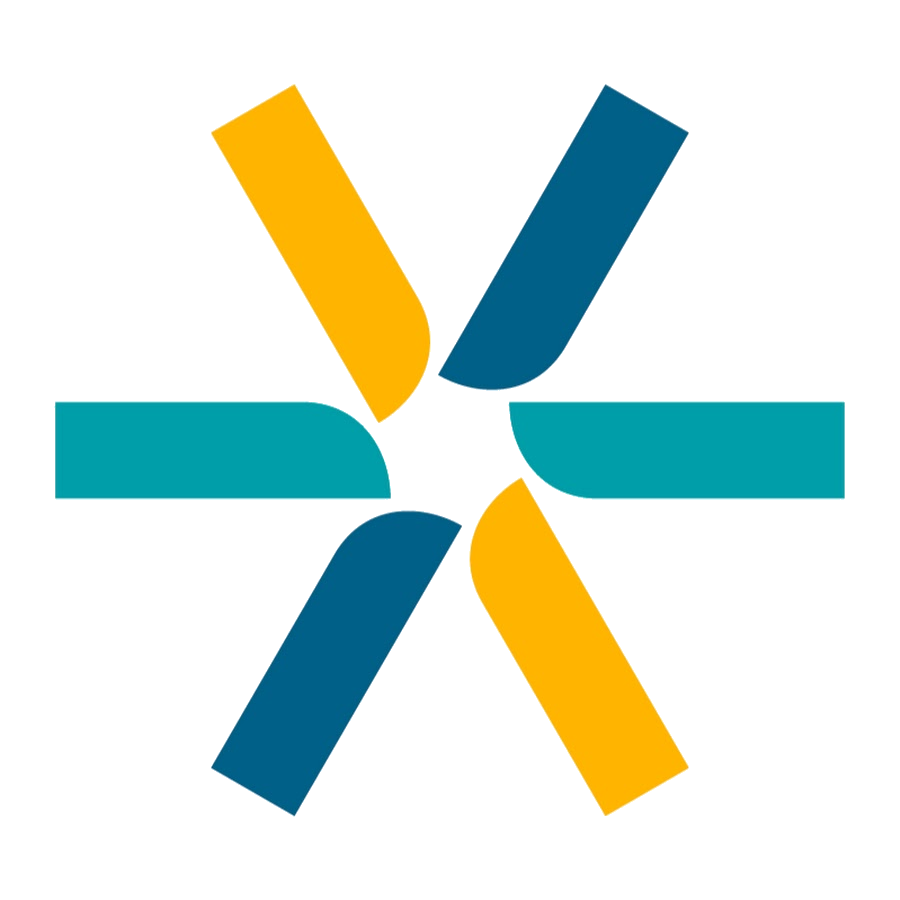
    <div>
        <h1 style="margin: 0; color: #ffffff; font-size: 1.45em; letter-spacing: 0.5px;">Aprendizaje Automático y Grandes Datos</h1>
        <h2 style="margin: 6px 0 2px 0; color: #cce4ff; font-size: 1.15em; font-weight: normal;">Árboles de decisión · demanda eléctrica (CAMMESA)</h2>
        <h3 style="margin: 0 0 8px 0; color: #a8d0f5; font-size: 1em; font-weight: normal;">Unidad 6 · Modelos basados en reglas</h3>
        <span style="background: #ffd700; color: #003366; font-weight: bold; font-size: 0.9em; padding: 3px 12px; border-radius: 20px;">⚡ Grupo 6 · Clase 35 sobre nuestro dataset</span>
    </div>
</div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Antes de empezar</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La pregunta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La misma de las clases 32 y 34: ¿la demanda de este agente va a caer más de un 15 % el mes que viene, y con qué probabilidad? Ahora con un modelo que se lee entero: una cadena de preguntas de sí o no, de la raíz a una hoja.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas filas, las mismas ocho predictoras, el mismo corte temporal y la misma prueba. Las referencias: la logística (AUC ~0,66) y los vecinos con k = 101 (AUC ~0,74).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se quiere resolver</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Qué hay adentro de un árbol (samples, value, gini), cómo elige cada corte (CART), por qué sin freno memoriza y cómo se lo frena (profundidad, mínimo por hoja, poda), y qué tiene de bueno (se lee, no necesita escalar, acepta faltantes) y de frágil (varianza, fronteras paralelas a los ejes, desequilibrio).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se muestra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas secciones de la clase 35: 1 · los datos → A · un árbol se lee (el ejemplo del material, Gini y entropía, la actividad) → B · cómo se construye → C · frenarlo → D · lo bueno y lo frágil → E · comparativo → F · usarlo, con la cadena de preguntas de cada fila.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cómo se decide</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Sobre la prueba, con las seis métricas, contra la línea de base, la logística y los vecinos. Los frenos se eligen con validación cruzada temporal (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">TimeSeriesSplit</code>).</td></tr></table></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué hay que saber antes de modelar</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Mismo desbalance (~17 % de caídas en entrenamiento, ~13 % en prueba) y mismas señales débiles. Tres cosas importan para un árbol:</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Muchas filas, muchos umbrales.</b> 31 000 filas con columnas casi continuas: en la raíz hay decenas de miles de cortes posibles, y un árbol sin freno puede llegar a miles de hojas.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Faltantes.</b> <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_hace_un_anio</code> falta en casi la mitad de las filas. Desde la versión 1.3, los árboles de scikit-learn aceptan faltantes sin imputar: en cada corte aprenden de qué lado mandarlos. Es la primera vez en la unidad que un modelo no necesita el imputador, y se usa así.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Lo del material.</b> El árbol de iris, Gini y entropía a mano, la actividad de las ocho filas y la figura de rotación con datos construidos se dejan igual que en la cátedra.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">1 · Los datos, listos</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Lo mismo que la clase 34, en una celda</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cargar, armar las predictoras, partir por fecha, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">registrar()</code> con seis métricas y dos tiempos, y las referencias: la línea de base, la logística (clase 32) y los vecinos con k = 101 (el elegido en la clase 34). Las referencias llevan imputador y escalador porque los necesitan; el árbol, no.</p></div>

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss

AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
pd.set_option("display.width", 130)
np.set_printoptions(suppress=True, precision=3)
warnings.filterwarnings("ignore", message="Skipping features without any observed values")   # primeros pliegues temporales sin var_hace_un_anio

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
base_lags = demanda[["serie", "periodo", "demanda_MWh"]]
for k in [1, 2, 12, 13]:
    t = base_lags.copy(); t["periodo"] = t["periodo"] + k
    demanda = demanda.merge(t.rename(columns={"demanda_MWh": f"lag{k}"}), on=["serie", "periodo"], how="left")

datos = demanda[demanda["lag1"] > 0].copy()
datos["ratio_dias"] = datos["periodo"].dt.days_in_month / (datos["periodo"] - 1).dt.days_in_month
datos["var_mes_ant"] = pd.Series(np.where(datos["lag2"] > 0, datos["lag1"] / datos["lag2"] - 1, np.nan), index=datos.index).clip(-1, 3)
datos["volatilidad"] = datos["var_mes_ant"].abs()
datos["var_hace_un_anio"] = pd.Series(np.where((datos["lag13"] > 0) & (datos["lag12"] >= 0), datos["lag12"] / datos["lag13"] - 1, np.nan), index=datos.index).clip(-1, 3)
datos["log_tamano"] = np.log10(datos["lag1"])
datos["mes_num"] = datos["periodo"].dt.month
datos["es_gran_usuario"] = (datos["categoria_demanda"] == "Gran Usuario").astype(int)
datos["es_residencial"] = (datos["categoria_tarifa"] == "Residencial").astype(int)
UMBRAL_CAIDA = 0.15
datos["cae_fuerte"] = (datos["demanda_MWh"] < (1 - UMBRAL_CAIDA) * datos["lag1"]).astype(int)
datos = datos.sort_values(["periodo", "serie"]).reset_index(drop=True)

PREDICTORAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num", "es_gran_usuario", "es_residencial"]
OBJETIVO = "cae_fuerte"
CORTE = pd.Period("2019-06", freq="M")
ent_mask = datos["periodo"] <= CORTE
X_ent, X_pru = datos.loc[ent_mask, PREDICTORAS], datos.loc[~ent_mask, PREDICTORAS]
y_ent, y_pru = datos.loc[ent_mask, OBJETIVO], datos.loc[~ent_mask, OBJETIVO]
CV = TimeSeriesSplit(n_splits=5)

def preparado(modelo):
    """Imputar, escalar y recién entonces el modelo."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), modelo)

resultados = {}
def guardar(nombre, prob, t_fit, t_pred, modelo, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    resultados[nombre] = {"exactitud": accuracy_score(y_pru, pred), "precisión": precision_score(y_pru, pred, zero_division=0),
                          "exhaustividad": recall_score(y_pru, pred), "F1": f1_score(y_pru, pred), "AUC": roc_auc_score(y_pru, prob),
                          "log-loss": log_loss(y_pru, prob), "ajuste (ms)": t_fit, "predicción (ms)": t_pred, "modelo": modelo}

def registrar(nombre, modelo, umbral=0.5, cols=None):
    cols = PREDICTORAS if cols is None else cols
    t0 = time.perf_counter(); modelo.fit(X_ent[cols], y_ent); t_fit = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); prob = modelo.predict_proba(X_pru[cols])[:, 1]; t_pred = (time.perf_counter() - t0) * 1000
    guardar(nombre, prob, t_fit, t_pred, modelo, umbral)
    return modelo

registrar("línea de base (mayoritaria)", DummyClassifier(strategy="most_frequent"))
logistica = registrar("regresión logística (clase 32)", preparado(LogisticRegression()))
vecinos = registrar("k vecinos, k=101 (clase 34)", preparado(KNeighborsClassifier(n_neighbors=101)))
print(f"{len(X_ent)} filas de entrenamiento ({y_ent.mean() * 100:.1f} % caídas) · {len(X_pru)} de prueba ({y_pru.sum()} caídas)")
for k in ["línea de base (mayoritaria)", "regresión logística (clase 32)", "k vecinos, k=101 (clase 34)"]:
    print(f"Referencia · {k:32s} AUC {resultados[k]['AUC']:.3f} · log-loss {resultados[k]['log-loss']:.3f}")

31415 filas de entrenamiento (17.1 % caídas) · 5982 de prueba (759 caídas)
Referencia · línea de base (mayoritaria)      AUC 0.500 · log-loss 4.573
Referencia · regresión logística (clase 32)   AUC 0.663 · log-loss 0.365
Referencia · k vecinos, k=101 (clase 34)      AUC 0.741 · log-loss 0.343


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">A · Un árbol se lee</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.1 · El árbol del material: samples, value, gini</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El árbol de iris de la diapositiva, igual que en la cátedra.</p></div>

|--- ancho de pétalo <= 0.80
|   |--- weights: [50.00, 0.00, 0.00] class: 0
|--- ancho de pétalo >  0.80
|   |--- ancho de pétalo <= 1.75
|   |   |--- weights: [0.00, 49.00, 5.00] class: 1
|   |--- ancho de pétalo >  1.75
|   |   |--- weights: [0.00, 1.00, 45.00] class: 2



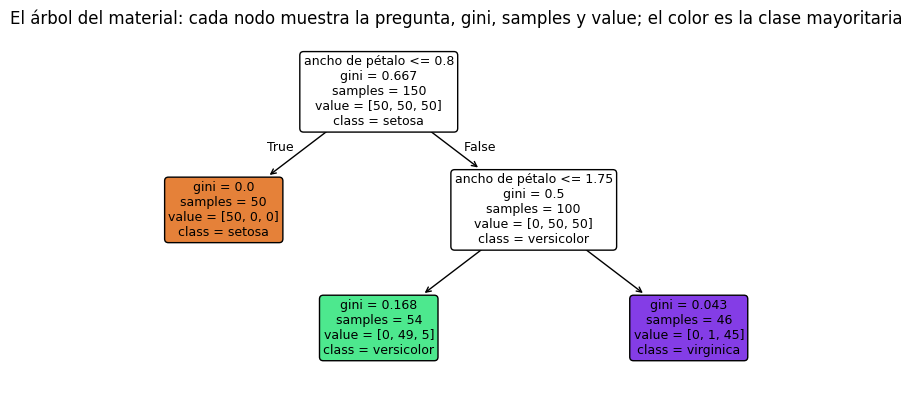

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()
X_iris, y_iris = iris.data[:, 2:], iris.target                            # largo y ancho del pétalo
arbol_iris = DecisionTreeClassifier(max_depth=2).fit(X_iris, y_iris)      # dos niveles, Gini (el defecto)
print(export_text(arbol_iris, feature_names=["largo de pétalo", "ancho de pétalo"], show_weights=True))
fig, ax = plt.subplots(figsize=(10, 4.6))
plot_tree(arbol_iris, feature_names=["largo de pétalo", "ancho de pétalo"], class_names=list(iris.target_names), filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("El árbol del material: cada nodo muestra la pregunta, gini, samples y value; el color es la clase mayoritaria")
plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.2 · Gini y entropía, a mano</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La impureza de cada nodo del árbol de iris, calculada a mano y comparada con la del árbol.</p></div>

,samples,value,gini (a mano),gini (del árbol),entropía (a mano)
raíz,150,"[50, 50, 50]",0.667,0.667,1.585
setosa (hoja),50,"[50, 0, 0]",0.000,0.000,0.000
"pétalo > 2,45",100,"[0, 50, 50]",0.500,0.500,1.000
versicolor (hoja),54,"[0, 49, 5]",0.168,0.168,0.445
virginica (hoja),46,"[0, 1, 45]",0.043,0.043,0.151


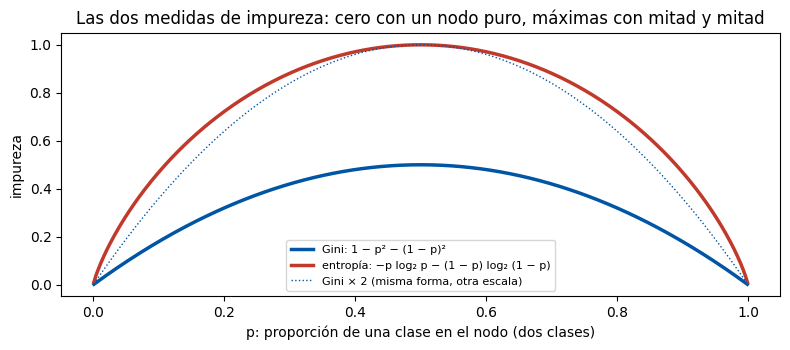

In [3]:
def gini(cuentas):
    p = np.asarray(cuentas, dtype=float) / np.sum(cuentas)
    return 1 - np.sum(p ** 2)
def entropia(cuentas):
    p = np.asarray(cuentas, dtype=float) / np.sum(cuentas); p = p[p > 0]
    return float(-np.sum(p * np.log2(p))) + 0.0
t = arbol_iris.tree_
nodos = pd.DataFrame({"samples": t.n_node_samples, "value": [list(v[0].astype(int)) for v in t.value * t.n_node_samples[:, None, None]],
                      "gini (a mano)": [gini(v[0]) for v in t.value], "gini (del árbol)": t.impurity, "entropía (a mano)": [entropia(v[0]) for v in t.value]},
                     index=["raíz", "setosa (hoja)", "pétalo > 2,45", "versicolor (hoja)", "virginica (hoja)"]).round(3)
display(nodos)
fig, ax = plt.subplots(figsize=(8, 3.6))
p = np.linspace(0.001, 0.999, 400)
ax.plot(p, 1 - p ** 2 - (1 - p) ** 2, color=AZUL, lw=2.5, label="Gini: 1 − p² − (1 − p)²")
ax.plot(p, -(p * np.log2(p) + (1 - p) * np.log2(1 - p)), color=ROJO, lw=2.5, label="entropía: −p log₂ p − (1 − p) log₂ (1 − p)")
ax.plot(p, (1 - p ** 2 - (1 - p) ** 2) * 2, color=AZUL, lw=1, ls=":", label="Gini × 2 (misma forma, otra escala)")
ax.set_xlabel("p: proporción de una clase en el nodo (dos clases)"); ax.set_ylabel("impureza"); ax.legend(fontsize=8)
ax.set_title("Las dos medidas de impureza: cero con un nodo puro, máximas con mitad y mitad")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.3 · La actividad: ocho filas, todos los cortes</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las ocho filas de la diapositiva, corte por corte, igual que en la cátedra.</p></div>

In [4]:
horas = np.array([2, 4, 5, 7, 3, 8, 6, 9]); asistencia = np.array([60, 55, 90, 95, 85, 70, 40, 88]); aprobo = np.array([0, 0, 1, 1, 0, 1, 0, 1])
filas = pd.DataFrame({"horas": horas, "asistencia": asistencia, "aprobó": aprobo}, index=[f"f{k}" for k in range(1, 9)])
def J(col, umbral, objetivo):
    """Impureza de Gini de cada lado del corte, ponderada por su tamaño."""
    izq, der = objetivo[col <= umbral], objetivo[col > umbral]
    g = lambda v: 1 - np.mean(v) ** 2 - (1 - np.mean(v)) ** 2
    return len(izq) / len(objetivo) * g(izq) + len(der) / len(objetivo) * g(der)
cortes = []
for nombre, col in [("horas", horas), ("asistencia", asistencia)]:
    valores = np.sort(np.unique(col)); umbrales = (valores[:-1] + valores[1:]) / 2                     # puntos medios
    for u in umbrales:
        cortes.append({"atributo": nombre, "umbral": u, "izquierda (≤)": f"{(col <= u).sum()} filas, {aprobo[col <= u].sum()} aprobaron",
                       "derecha (>)": f"{(col > u).sum()} filas, {aprobo[col > u].sum()} aprobaron", "J": round(J(col, u, aprobo), 3)})
cortes = pd.DataFrame(cortes)
display(cortes.style.format({"umbral": "{:g}", "J": "{:.3f}"}).background_gradient(subset=["J"], cmap="RdYlGn_r").set_caption("Los catorce cortes posibles en la raíz, con la impureza ponderada J de cada uno: cuatro empatan en 0,2"))
for semilla in [0, 2]:
    arbol_mano = DecisionTreeClassifier(max_depth=2, random_state=semilla).fit(filas[["horas", "asistencia"]], aprobo)
    print(f"CART con random_state={semilla}:"); print(export_text(arbol_mano, feature_names=["horas", "asistencia"]))

,atributo,umbral,izquierda (≤),derecha (>),J
0,horas,2.5,"1 filas, 0 aprobaron","7 filas, 4 aprobaron",0.429
1,horas,3.5,"2 filas, 0 aprobaron","6 filas, 4 aprobaron",0.333
2,horas,4.5,"3 filas, 0 aprobaron","5 filas, 4 aprobaron",0.200
3,horas,5.5,"4 filas, 1 aprobaron","4 filas, 3 aprobaron",0.375
4,horas,6.5,"5 filas, 1 aprobaron","3 filas, 3 aprobaron",0.200
5,horas,7.5,"6 filas, 2 aprobaron","2 filas, 2 aprobaron",0.333
6,horas,8.5,"7 filas, 3 aprobaron","1 filas, 1 aprobaron",0.429
7,asistencia,47.5,"1 filas, 0 aprobaron","7 filas, 4 aprobaron",0.429
8,asistencia,57.5,"2 filas, 0 aprobaron","6 filas, 4 aprobaron",0.333
9,asistencia,65,"3 filas, 0 aprobaron","5 filas, 4 aprobaron",0.200


CART con random_state=0:
|--- asistencia <= 65.00
|   |--- class: 0
|--- asistencia >  65.00
|   |--- horas <= 4.00
|   |   |--- class: 0
|   |--- horas >  4.00
|   |   |--- class: 1

CART con random_state=2:
|--- horas <= 4.50
|   |--- class: 0
|--- horas >  4.50
|   |--- asistencia <= 55.00
|   |   |--- class: 0
|   |--- asistencia >  55.00
|   |   |--- class: 1



<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">B · Cómo se construye: CART</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.1 · La sentencia, sobre nuestros datos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">DecisionTreeClassifier(max_depth=2, random_state=2026).fit(X, y)</code>: dos niveles, cuatro hojas, <b>sin imputar</b>. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict_proba</code> devuelve la proporción de caídas en la hoja: cuatro valores posibles de p̂.</p></div>

|--- volatilidad <= 0.15
|   |--- var_hace_un_anio <= -0.16
|   |   |--- weights: [707.00, 336.00] class: 0
|   |--- var_hace_un_anio >  -0.16
|   |   |--- weights: [16192.00, 2128.00] class: 0
|--- volatilidad >  0.15
|   |--- var_hace_un_anio <= -0.09
|   |   |--- weights: [6574.00, 2488.00] class: 0
|   |--- var_hace_un_anio >  -0.09
|   |   |--- weights: [2562.00, 428.00] class: 0

nodo 0: volatilidad ≤ 0.153 · los faltantes van a la derecha (>)
nodo 1: var_hace_un_anio ≤ -0.155 · los faltantes van a la derecha (>)
nodo 4: var_hace_un_anio ≤ -0.087 · los faltantes van a la izquierda (≤)
Valores posibles de p̂ con 4 hojas: [0.116, 0.143, 0.275, 0.322] · AUC 0.688 (logística 0.663) · log-loss 0.355


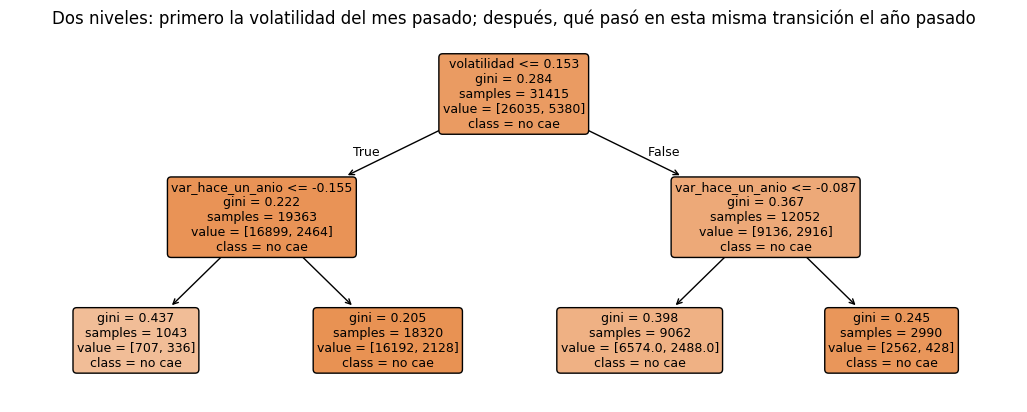

In [5]:
arbol2 = registrar("árbol, profundidad 2", DecisionTreeClassifier(max_depth=2, random_state=2026))
print(export_text(arbol2, feature_names=PREDICTORAS, show_weights=True))
prob2 = arbol2.predict_proba(X_pru)[:, 1]
t2 = arbol2.tree_
for nodo in [0, t2.children_left[0], t2.children_right[0]]:
    print(f"nodo {nodo}: {PREDICTORAS[t2.feature[nodo]]} ≤ {t2.threshold[nodo]:.3f} · los faltantes van a la {'izquierda (≤)' if t2.missing_go_to_left[nodo] else 'derecha (>)'}")
print(f"Valores posibles de p̂ con 4 hojas: {[float(v) for v in sorted(set(prob2.round(3)))]} · AUC {resultados['árbol, profundidad 2']['AUC']:.3f} (logística {resultados['regresión logística (clase 32)']['AUC']:.3f}) · log-loss {resultados['árbol, profundidad 2']['log-loss']:.3f}")
fig, ax = plt.subplots(figsize=(13, 4.8))
plot_tree(arbol2, feature_names=PREDICTORAS, class_names=["no cae", "cae"], filled=True, rounded=True, fontsize=9, ax=ax, impurity=True)
ax.set_title("Dos niveles: primero la volatilidad del mes pasado; después, qué pasó en esta misma transición el año pasado")
plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con <b>dos preguntas</b> el árbol ya ordena mejor que la logística de ocho columnas. La raíz pregunta si la demanda se movió más de ~15 % el mes pasado (para arriba o para abajo): los agentes estables casi nunca caen fuerte. La segunda pregunta mira el año pasado: si en esta misma transición la demanda bajó, el riesgo se duplica o triplica. Es una interacción («volátil <b>y</b> con antecedente de baja») que la logística, que suma, no podía expresar con un coeficiente.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Ninguna hoja tiene mayoría de caídas, así que con el umbral de 0,5 este árbol nunca predice «cae»; pero su hoja más riesgosa tiene ~32 % de caídas contra ~17 % de base. Los faltantes de <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_hace_un_anio</code> van al lado que el árbol aprendió que les conviene.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.2 · El mejor corte de la raíz, a mano</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Lo que CART hace en la raíz: para cada columna, todos los umbrales (puntos medios entre valores consecutivos), y para cada uno J = impureza de cada lado ponderada por su tamaño. Con faltantes, se prueban los dos destinos (izquierda o derecha) y se queda con el mejor, como hace la biblioteca. Con decenas de miles de umbrales no se puede hacer fila por fila: se usan sumas acumuladas sobre las filas ordenadas, que dan el mismo resultado.</p></div>

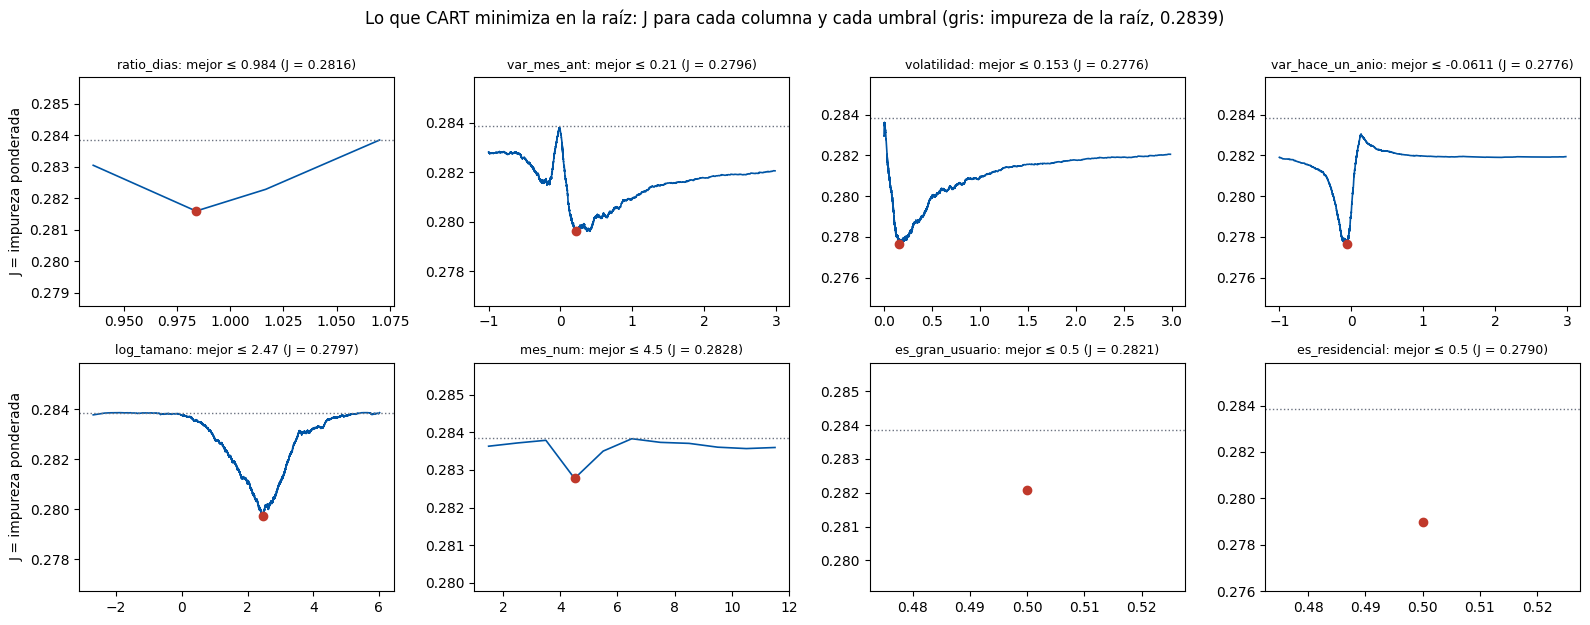

,columna,umbrales probados,mejor umbral,J
0,volatilidad,29259,0.1527,0.2776
1,var_hace_un_anio,13941,-0.0611,0.2776
2,es_residencial,1,0.5000,0.2790
3,var_mes_ant,29261,0.2103,0.2796
4,log_tamano,30821,2.4656,0.2797
5,ratio_dias,4,0.9839,0.2816
6,es_gran_usuario,1,0.5000,0.2821
7,mes_num,11,4.5000,0.2828


Umbrales probados en total: 103,299 · el mejor: volatilidad ≤ 0.1527 · el árbol de B.1 puso en la raíz: volatilidad ≤ 0.1527


In [6]:
def gini2(n, p):
    """Gini de un nodo con n filas y p positivas (vectorizado)."""
    q = np.where(n > 0, p / np.maximum(n, 1), 0)
    return 1 - q ** 2 - (1 - q) ** 2
def J_columna(col):
    """Todos los umbrales de una columna y la J de cada uno (los faltantes, al lado que más conviene)."""
    x, yv = X_ent[col].to_numpy(dtype=float), y_ent.to_numpy()
    falt = np.isnan(x); n, nm, pm = len(yv), falt.sum(), yv[falt].sum()
    orden = np.argsort(x[~falt], kind="stable"); xs, ys = x[~falt][orden], yv[~falt][orden]
    corte = np.where(np.diff(xs) > 0)[0]                                       # entre xs[i] y xs[i+1] hay un umbral posible
    umbrales = (xs[corte] + xs[corte + 1]) / 2
    nl = corte + 1; pl = np.cumsum(ys)[corte]; nr = len(xs) - nl; pr = ys.sum() - pl
    J_izq = ((nl + nm) * gini2(nl + nm, pl + pm) + nr * gini2(nr, pr)) / n         # faltantes a la izquierda
    J_der = (nl * gini2(nl, pl) + (nr + nm) * gini2(nr + nm, pr + pm)) / n         # faltantes a la derecha
    return umbrales, np.minimum(J_izq, J_der)
g_raiz = gini2(np.array([len(y_ent)]), np.array([y_ent.sum()]))[0]
mejores = []
fig, ejes = plt.subplots(2, 4, figsize=(16, 6.2))
for ax, col in zip(ejes.ravel(), PREDICTORAS):
    umbrales, js = J_columna(col); k = int(np.argmin(js))
    mejores.append({"columna": col, "umbrales probados": len(umbrales), "mejor umbral": umbrales[k], "J": js[k]})
    ax.plot(umbrales, js, color=AZUL, lw=1.2); ax.scatter([umbrales[k]], [js[k]], color=ROJO, zorder=5)
    ax.axhline(g_raiz, color=GRIS, ls=":", lw=1); ax.set_title(f"{col}: mejor ≤ {umbrales[k]:.3g} (J = {js[k]:.4f})", fontsize=9)
    ax.set_ylim(min(js.min(), g_raiz) - 0.003, g_raiz + 0.002)
ejes[0, 0].set_ylabel("J = impureza ponderada"); ejes[1, 0].set_ylabel("J = impureza ponderada")
fig.suptitle(f"Lo que CART minimiza en la raíz: J para cada columna y cada umbral (gris: impureza de la raíz, {g_raiz:.4f})", y=1.0)
plt.tight_layout(); plt.show()
mejores = pd.DataFrame(mejores).sort_values("J").reset_index(drop=True)
display(mejores.round(4))
print(f"Umbrales probados en total: {mejores['umbrales probados'].sum():,} · el mejor: {mejores.iloc[0]['columna']} ≤ {mejores.iloc[0]['mejor umbral']:.4f} · "
      f"el árbol de B.1 puso en la raíz: {PREDICTORAS[arbol2.tree_.feature[0]]} ≤ {arbol2.tree_.threshold[0]:.4f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El mínimo de los mínimos coincide con la raíz del árbol de B.1. La impureza baja muy poco: ninguna pregunta sola separa bien, que es lo que ya se sabía de este problema. Las curvas de <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_gran_usuario</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_residencial</code> tienen un solo punto (solo hay un umbral posible en una columna 0/1), y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">mes_num</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code> tienen muy pocos.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.3 · Cuánto cuesta, y qué tan hondo llega</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El tiempo de ajuste sin freno con cada vez más filas, el de predicción sobre la prueba, y hasta dónde crece el árbol sin freno. Los tiempos son de esta máquina; lo que importa es la forma.</p></div>

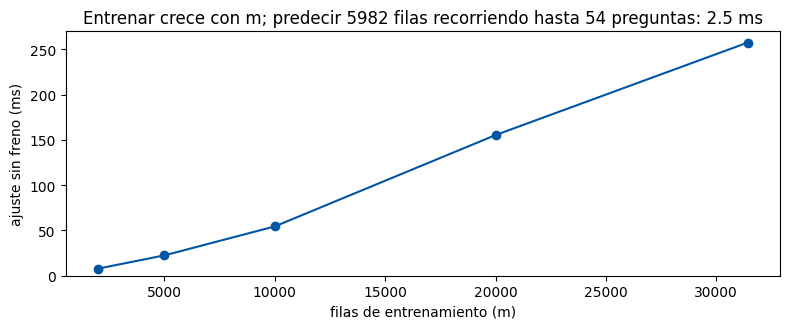

Sin freno: profundidad 54 · 5,970 hojas · 11,939 nodos
Para comparar: los vecinos tardaron 1052 ms en predecir la misma prueba


In [7]:
tamanos = [2000, 5000, 10000, 20000, len(X_ent)]; t_ajuste = []
DecisionTreeClassifier(random_state=2026).fit(X_ent.iloc[:2000], y_ent.iloc[:2000])
for m in tamanos:
    repeticiones = []
    for _ in range(3):
        t0 = time.perf_counter(); DecisionTreeClassifier(random_state=2026).fit(X_ent.iloc[:m], y_ent.iloc[:m]); repeticiones.append((time.perf_counter() - t0) * 1000)
    t_ajuste.append(min(repeticiones))
sin_freno = DecisionTreeClassifier(random_state=2026).fit(X_ent, y_ent)
t0 = time.perf_counter(); sin_freno.predict(X_pru); t_pred = (time.perf_counter() - t0) * 1000
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(tamanos, t_ajuste, marker="o", color=AZUL); ax.set_xlabel("filas de entrenamiento (m)"); ax.set_ylabel("ajuste sin freno (ms)"); ax.set_ylim(0)
ax.set_title(f"Entrenar crece con m; predecir {len(X_pru)} filas recorriendo hasta {sin_freno.get_depth()} preguntas: {t_pred:.1f} ms")
plt.tight_layout(); plt.show()
print(f"Sin freno: profundidad {sin_freno.get_depth()} · {sin_freno.get_n_leaves():,} hojas · {sin_freno.tree_.node_count:,} nodos")
print(f"Para comparar: los vecinos tardaron {resultados['k vecinos, k=101 (clase 34)']['predicción (ms)']:.0f} ms en predecir la misma prueba")

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">C · Frenar el árbol</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.1 · Sin freno, memoriza</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Todos los defectos: crece hasta que cada hoja es pura o no se puede dividir.</p></div>

In [8]:
registrar("árbol sin freno", DecisionTreeClassifier(random_state=2026))
prob_sf = resultados["árbol sin freno"]["modelo"].predict_proba(X_pru)[:, 1]
print(f"Exactitud sobre entrenamiento: {accuracy_score(y_ent, sin_freno.predict(X_ent)) * 100:.1f} % · sobre prueba: {resultados['árbol sin freno']['exactitud'] * 100:.1f} % (la línea de base: {resultados['línea de base (mayoritaria)']['exactitud'] * 100:.1f} %)")
print(f"AUC sobre prueba: {resultados['árbol sin freno']['AUC']:.3f} (logística {resultados['regresión logística (clase 32)']['AUC']:.3f}) · log-loss {resultados['árbol sin freno']['log-loss']:.3f} (logística {resultados['regresión logística (clase 32)']['log-loss']:.3f})")
hojas_n = sin_freno.tree_.n_node_samples[sin_freno.tree_.children_left == -1]
print(f"Filas de prueba con p̂ exactamente 0 o 1: {np.mean((prob_sf == 0) | (prob_sf == 1)) * 100:.0f} % · hojas con una sola fila de entrenamiento: {(hojas_n == 1).sum():,} de {sin_freno.get_n_leaves():,}")
print(f"Filas de entrenamiento repetidas: {X_ent.duplicated().sum()} (casi ninguna: las predictoras son continuas, así que el árbol puede aislar cada fila)")

Exactitud sobre entrenamiento: 100.0 % · sobre prueba: 79.5 % (la línea de base: 87.3 %)
AUC sobre prueba: 0.577 (logística 0.663) · log-loss 7.399 (logística 0.365)
Filas de prueba con p̂ exactamente 0 o 1: 100 % · hojas con una sola fila de entrenamiento: 2,530 de 5,970
Filas de entrenamiento repetidas: 35 (casi ninguna: las predictoras son continuas, así que el árbol puede aislar cada fila)


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sin freno, el árbol le dedica una hoja a casi cada fila: miles de hojas de una sola fila, 100 % de exactitud en entrenamiento. Sobre prueba el AUC se derrumba muy por debajo de la logística, y el log-loss se dispara: casi todas las predicciones son 0 o 1, y cuando se equivoca paga el máximo. Es más extremo que en la cátedra porque allá había filas repetidas con distinto resultado que ponían un techo; acá casi no hay, y el árbol puede memorizar todo.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.2 · El primer freno: la profundidad</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">max_depth</code> de 1 a 20 y sin límite: AUC de entrenamiento, de validación cruzada temporal, de prueba (se mira, no decide) y cantidad de hojas.</p></div>

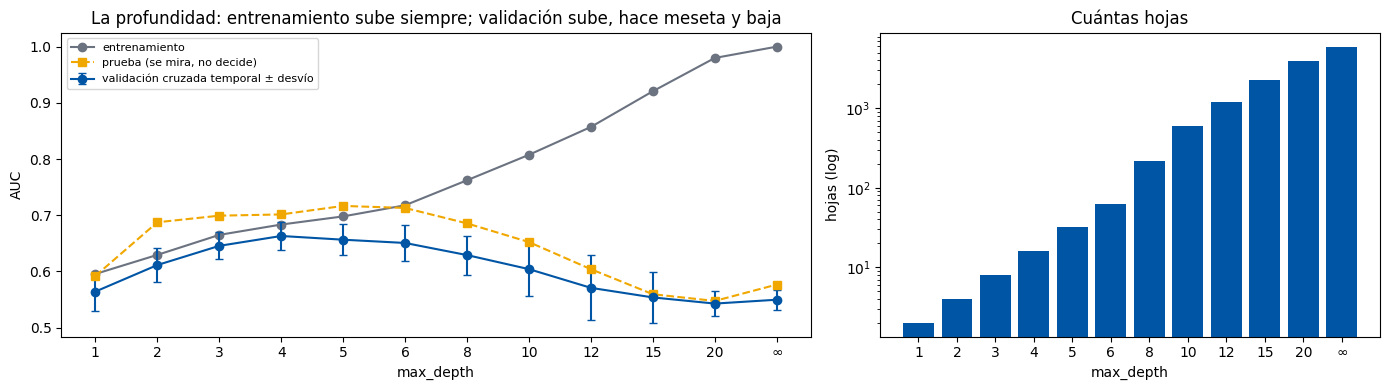

,max_depth,AUC entrenamiento,AUC validación,desvío,AUC prueba,hojas,profundidad real
0,1,0.596,0.564,0.034,0.592,2,1
1,2,0.630,0.611,0.030,0.688,4,2
2,3,0.665,0.646,0.024,0.699,8,3
3,4,0.683,0.663,0.025,0.701,16,4
4,5,0.698,0.657,0.028,0.717,32,5
5,6,0.718,0.651,0.032,0.713,63,6
6,8,0.762,0.629,0.035,0.686,218,8
7,10,0.808,0.604,0.048,0.652,595,10
8,12,0.857,0.571,0.058,0.604,1194,12
9,15,0.921,0.554,0.045,0.560,2259,15


In [9]:
profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
filas_p = []
for d in profundidades:
    m = DecisionTreeClassifier(max_depth=d, random_state=2026)
    cv = cross_val_score(m, X_ent, y_ent, cv=CV, scoring="roc_auc"); m.fit(X_ent, y_ent)
    filas_p.append({"max_depth": d if d else "∞", "AUC entrenamiento": roc_auc_score(y_ent, m.predict_proba(X_ent)[:, 1]), "AUC validación": cv.mean(), "desvío": cv.std(),
                    "AUC prueba": roc_auc_score(y_pru, m.predict_proba(X_pru)[:, 1]), "hojas": m.get_n_leaves(), "profundidad real": m.get_depth()})
curva_p = pd.DataFrame(filas_p)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 2]})
xs = range(len(profundidades)); etiquetas = [str(d) if d else "∞" for d in profundidades]
a.plot(xs, curva_p["AUC entrenamiento"], marker="o", color=GRIS, label="entrenamiento")
a.errorbar(xs, curva_p["AUC validación"], yerr=curva_p["desvío"], marker="o", color=AZUL, capsize=3, label="validación cruzada temporal ± desvío")
a.plot(xs, curva_p["AUC prueba"], marker="s", color=AMBAR, ls="--", label="prueba (se mira, no decide)")
a.set_xticks(list(xs)); a.set_xticklabels(etiquetas); a.set_xlabel("max_depth"); a.set_ylabel("AUC"); a.legend(fontsize=8)
a.set_title("La profundidad: entrenamiento sube siempre; validación sube, hace meseta y baja")
b.bar(xs, curva_p["hojas"], color=AZUL); b.set_yscale("log"); b.set_xticks(list(xs)); b.set_xticklabels(etiquetas); b.set_xlabel("max_depth"); b.set_ylabel("hojas (log)"); b.set_title("Cuántas hojas")
plt.tight_layout(); plt.show()
display(curva_p.round(3))

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.3 · El segundo freno, y los dos juntos con la cuadrícula</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">min_samples_leaf</code> solo, de 1 a 1000; y después los dos frenos con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GridSearchCV</code> y pliegues temporales. Con tantas filas, los mínimos útiles son mucho más grandes que en la cátedra.</p></div>

In [10]:
filas_h = []
for h in [1, 10, 50, 100, 200, 500, 1000]:
    m = DecisionTreeClassifier(min_samples_leaf=h, random_state=2026)
    cv = cross_val_score(m, X_ent, y_ent, cv=CV, scoring="roc_auc"); m.fit(X_ent, y_ent)
    filas_h.append({"min_samples_leaf": h, "AUC validación": cv.mean(), "AUC prueba": roc_auc_score(y_pru, m.predict_proba(X_pru)[:, 1]), "hojas": m.get_n_leaves(), "profundidad": m.get_depth()})
display(pd.DataFrame(filas_h).round(3))
cuadricula = GridSearchCV(DecisionTreeClassifier(random_state=2026), {"max_depth": [3, 4, 6, 8, 10, 12, None], "min_samples_leaf": [20, 50, 100, 200, 500]},
                          cv=CV, scoring="roc_auc").fit(X_ent, y_ent)
params = cuadricula.best_params_
NOMBRE_ARBOL = f"árbol, profundidad {params['max_depth']}, mínimo {params['min_samples_leaf']} por hoja (validación)"
print(f"Mejor combinación: {params} · AUC de validación {cuadricula.best_score_:.3f}")
arbol = registrar(NOMBRE_ARBOL, DecisionTreeClassifier(random_state=2026, **params))
print(f"Sobre prueba: AUC {resultados[NOMBRE_ARBOL]['AUC']:.3f} · log-loss {resultados[NOMBRE_ARBOL]['log-loss']:.3f} · {arbol.get_n_leaves()} hojas, profundidad {arbol.get_depth()}")
print(f"Referencias: logística {resultados['regresión logística (clase 32)']['AUC']:.3f} / {resultados['regresión logística (clase 32)']['log-loss']:.3f} · vecinos {resultados['k vecinos, k=101 (clase 34)']['AUC']:.3f} / {resultados['k vecinos, k=101 (clase 34)']['log-loss']:.3f}")
mapa = pd.DataFrame(cuadricula.cv_results_).pivot(index="param_min_samples_leaf", columns="param_max_depth", values="mean_test_score")
mapa.columns = [str(int(c_)) if pd.notna(c_) else "∞" for c_ in mapa.columns]; mapa.index.name, mapa.columns.name = "min_samples_leaf", "max_depth"
display(mapa.style.format("{:.3f}").background_gradient(cmap="RdYlGn", axis=None).set_caption("AUC de validación temporal: filas min_samples_leaf, columnas max_depth"))

,min_samples_leaf,AUC validación,AUC prueba,hojas,profundidad
0,1,0.550,0.577,5970,54
1,10,0.609,0.664,1835,33
2,50,0.658,0.706,462,25
3,100,0.671,0.717,236,19
4,200,0.673,0.722,120,17
5,500,0.665,0.707,48,14
6,1000,0.612,0.720,24,9


Mejor combinación: {'max_depth': 10, 'min_samples_leaf': 200} · AUC de validación 0.674
Sobre prueba: AUC 0.724 · log-loss 0.343 · 98 hojas, profundidad 10
Referencias: logística 0.663 / 0.365 · vecinos 0.741 / 0.343


max_depth,∞,3,4,6,8,10,12
min_samples_leaf,,,,,,,
20,0.638,0.646,0.661,0.654,0.646,0.641,0.640
50,0.658,0.646,0.662,0.660,0.664,0.658,0.660
100,0.671,0.641,0.656,0.670,0.671,0.672,0.672
200,0.673,0.644,0.658,0.670,0.672,0.674,0.673
500,0.665,0.650,0.656,0.665,0.665,0.665,0.665


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con un mínimo por hoja grande, la profundidad deja de importar: el árbol no puede crecer de más porque cada hoja necesita cientos de filas. El mejor árbol queda <b>entre la logística y los vecinos</b> en AUC, y con un log-loss parecido al de ellos: el mismo orden que en la cátedra.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Con y sin mínimo por hoja: la frontera</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Dos columnas (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">log_tamano</code>, sin escalar: el árbol no lo necesita) y tres árboles. El color es la probabilidad de caída. Todas las fronteras son paralelas a los ejes.</p></div>

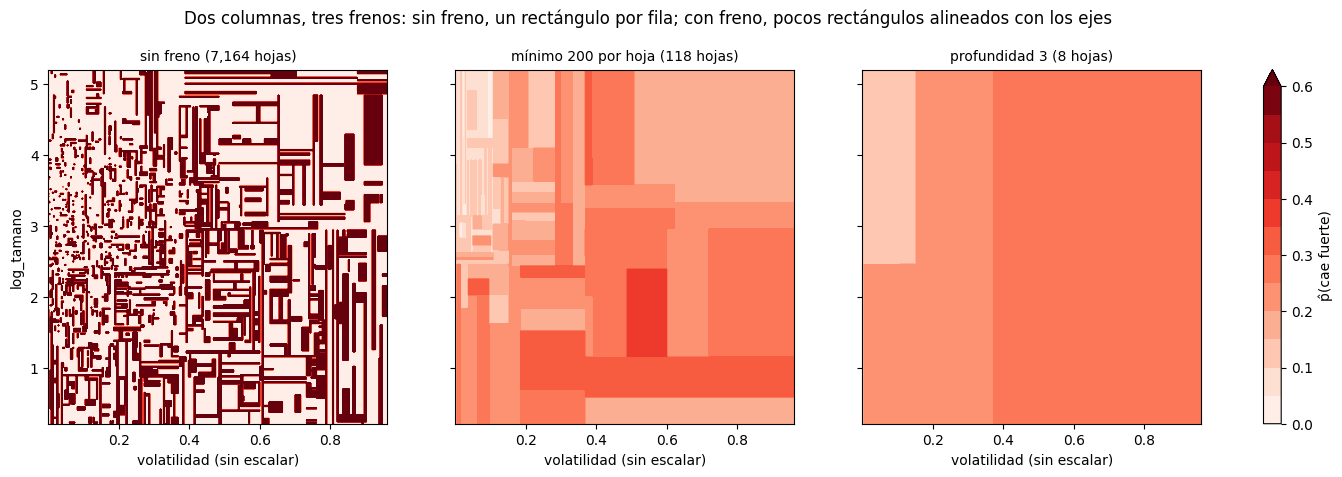

In [11]:
DOS = ["volatilidad", "log_tamano"]
lim1, lim2 = np.nanpercentile(X_ent[DOS[0]], [1, 97]), np.nanpercentile(X_ent[DOS[1]], [2, 99])
g1, g2 = np.meshgrid(np.linspace(*lim1, 300), np.linspace(*lim2, 300))
grilla = pd.DataFrame(np.c_[g1.ravel(), g2.ravel()], columns=DOS)
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, (arbol_f, lectura) in zip(ejes, [(DecisionTreeClassifier(random_state=2026), "sin freno"), (DecisionTreeClassifier(min_samples_leaf=200, random_state=2026), "mínimo 200 por hoja"), (DecisionTreeClassifier(max_depth=3, random_state=2026), "profundidad 3")]):
    arbol_f.fit(X_ent[DOS], y_ent)
    im = ax.contourf(g1, g2, arbol_f.predict_proba(grilla)[:, 1].reshape(g1.shape), levels=np.linspace(0, 0.6, 13), cmap="Reds", extend="max")
    ax.set_xlim(*lim1); ax.set_ylim(*lim2); ax.set_title(f"{lectura} ({arbol_f.get_n_leaves():,} hojas)", fontsize=10); ax.set_xlabel("volatilidad (sin escalar)")
ejes[0].set_ylabel("log_tamano")
fig.colorbar(im, ax=ejes, label="p̂(cae fuerte)", fraction=0.02)
fig.suptitle("Dos columnas, tres frenos: sin freno, un rectángulo por fila; con freno, pocos rectángulos alineados con los ejes", y=1.01)
plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.4 · Crecer y podar</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Dejar crecer sin freno y podar por costo-complejidad (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ccp_alpha</code>), con α elegido por validación temporal. Con miles de hojas, el camino de poda tiene miles de α; se prueban unos pocos repartidos.</p></div>

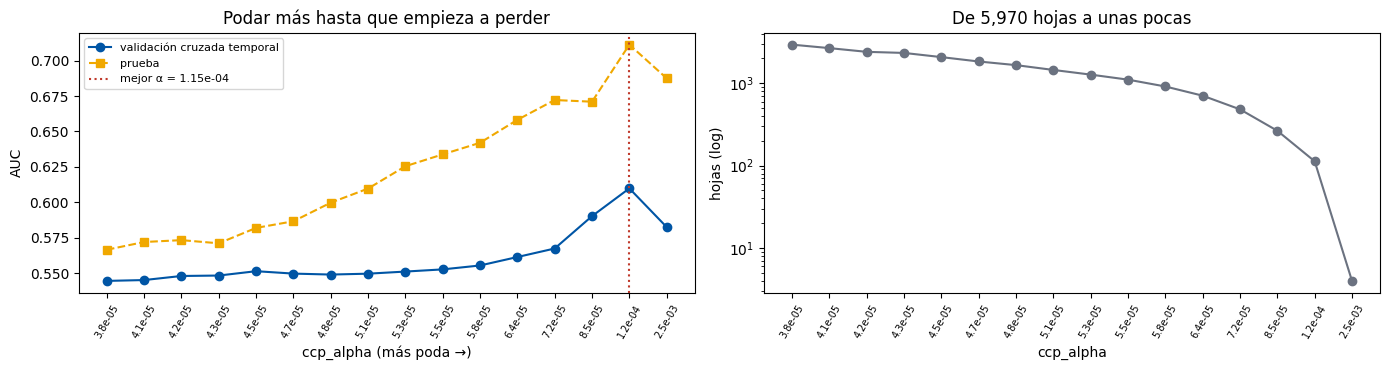

Camino de poda: 2,105 valores de α · mejor α = 1.15e-04 → 113 hojas, profundidad 14 · AUC prueba 0.711, log-loss 0.366


In [12]:
camino = sin_freno.cost_complexity_pruning_path(X_ent, y_ent)
alphas = np.unique(np.quantile(camino.ccp_alphas, np.linspace(0.5, 0.999, 16)))
filas_a = []
for alpha in alphas:
    m = DecisionTreeClassifier(random_state=2026, ccp_alpha=alpha)
    cv = cross_val_score(m, X_ent, y_ent, cv=CV, scoring="roc_auc"); m.fit(X_ent, y_ent)
    filas_a.append({"ccp_alpha": alpha, "AUC validación": cv.mean(), "AUC prueba": roc_auc_score(y_pru, m.predict_proba(X_pru)[:, 1]), "hojas": m.get_n_leaves(), "profundidad": m.get_depth()})
poda = pd.DataFrame(filas_a); mejor_alpha = poda.loc[poda["AUC validación"].idxmax(), "ccp_alpha"]
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 3.8))
xs_a = range(len(poda)); etiquetas_a = [f"{v:.1e}" for v in poda["ccp_alpha"]]
a.plot(xs_a, poda["AUC validación"], marker="o", color=AZUL, label="validación cruzada temporal"); a.plot(xs_a, poda["AUC prueba"], marker="s", ls="--", color=AMBAR, label="prueba")
a.axvline(int(poda["AUC validación"].idxmax()), color=ROJO, ls=":", label=f"mejor α = {mejor_alpha:.2e}"); a.set_xticks(list(xs_a)); a.set_xticklabels(etiquetas_a, rotation=60, fontsize=7)
a.set_xlabel("ccp_alpha (más poda →)"); a.set_ylabel("AUC"); a.legend(fontsize=8); a.set_title("Podar más hasta que empieza a perder")
b.plot(xs_a, poda["hojas"], marker="o", color=GRIS); b.set_yscale("log"); b.set_xticks(list(xs_a)); b.set_xticklabels(etiquetas_a, rotation=60, fontsize=7); b.set_xlabel("ccp_alpha"); b.set_ylabel("hojas (log)")
b.set_title(f"De {sin_freno.get_n_leaves():,} hojas a unas pocas")
plt.tight_layout(); plt.show()
NOMBRE_PODA = f"árbol podado, α = {mejor_alpha:.2e}"
registrar(NOMBRE_PODA, DecisionTreeClassifier(random_state=2026, ccp_alpha=mejor_alpha))
m = resultados[NOMBRE_PODA]["modelo"]
print(f"Camino de poda: {len(camino.ccp_alphas):,} valores de α · mejor α = {mejor_alpha:.2e} → {m.get_n_leaves()} hojas, profundidad {m.get_depth()} · AUC prueba {resultados[NOMBRE_PODA]['AUC']:.3f}, log-loss {resultados[NOMBRE_PODA]['log-loss']:.3f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.5 · Árbol de regresión: la demanda en MWh</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El mismo árbol con hojas que promedian, sobre el problema de las clases 29 y 31. Primero la escalera sobre una columna (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code>), después la tabla contra las referencias: la recta ~9 800 MWh, grado 2 + Lasso ~8 300, los vecinos ~13 000.</p></div>

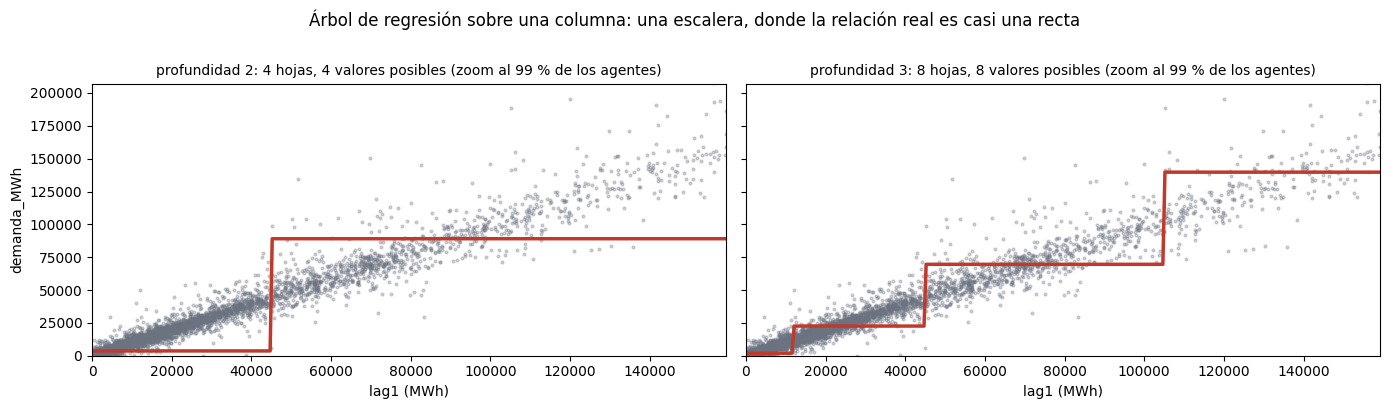

Referencia, la recta de la clase 29 recalculada: RMSE = 9,825 MWh


RMSE (MWh)             hojas        
min_samples_leaf                           1        10       1       10
columnas                 max_depth                                     
seis columnas (clase 29) 4            14707.0  16180.0     16.0    15.0
                         8            16139.0  15795.0    174.0   119.0
                         12           16295.0  15818.0   1049.0   478.0
                         ∞            17175.0  15819.0  31454.0  2520.0
solo lag1                4            13227.0  16137.0     16.0    15.0
                         8            15052.0  15719.0    182.0   135.0
                         12           15759.0  15736.0   1150.0   581.0
                         ∞            15934.0  15738.0  30825.0  2481.0

In [13]:
reg = demanda[demanda["lag1"].notna()].copy()
reg["mes_num"] = reg["periodo"].dt.month
reg["es_gran_usuario"] = (reg["categoria_demanda"] == "Gran Usuario").astype(int)
reg["es_residencial"] = (reg["categoria_tarifa"] == "Residencial").astype(int)
P29 = ["lag1", "lag2", "lag12", "mes_num", "es_gran_usuario", "es_residencial"]
r_ent = reg["periodo"] <= CORTE
def rmse(a, b): return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))
una = reg.loc[r_ent, ["lag1"]]
lim = una["lag1"].quantile(0.99)
xs_r = pd.DataFrame({"lag1": np.linspace(0, una["lag1"].max(), 2000)})
fig, ejes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, d in zip(ejes, [2, 3]):
    r = DecisionTreeRegressor(max_depth=d, random_state=2026).fit(una, reg.loc[r_ent, "demanda_MWh"])
    ax.scatter(una["lag1"], reg.loc[r_ent, "demanda_MWh"], s=4, color=GRIS, alpha=0.3); ax.plot(xs_r, r.predict(xs_r), color=ROJO, lw=2.5)
    ax.set_xlim(0, lim); ax.set_ylim(0, 1.3 * lim)
    ax.set_title(f"profundidad {d}: {r.get_n_leaves()} hojas, {r.get_n_leaves()} valores posibles (zoom al 99 % de los agentes)", fontsize=10); ax.set_xlabel("lag1 (MWh)")
ejes[0].set_ylabel("demanda_MWh")
fig.suptitle("Árbol de regresión sobre una columna: una escalera, donde la relación real es casi una recta", y=1.01)
plt.tight_layout(); plt.show()
filas_r = []
for cols, etiqueta in [(P29, "seis columnas (clase 29)"), (["lag1"], "solo lag1")]:
    for d in [4, 8, 12, None]:
        for h in [1, 10]:
            m = DecisionTreeRegressor(max_depth=d, min_samples_leaf=h, random_state=2026).fit(reg.loc[r_ent, cols], reg.loc[r_ent, "demanda_MWh"])
            filas_r.append({"columnas": etiqueta, "max_depth": d if d else "∞", "min_samples_leaf": h, "RMSE (MWh)": rmse(reg.loc[~r_ent, "demanda_MWh"], m.predict(reg.loc[~r_ent, cols])), "hojas": m.get_n_leaves()})
from sklearn.linear_model import LinearRegression
recta29 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()).fit(reg.loc[r_ent, P29], reg.loc[r_ent, "demanda_MWh"])
print(f"Referencia, la recta de la clase 29 recalculada: RMSE = {rmse(reg.loc[~r_ent, 'demanda_MWh'], recta29.predict(reg.loc[~r_ent, P29])):,.0f} MWh")
pd.DataFrame(filas_r).pivot(index=["columnas", "max_depth"], columns="min_samples_leaf", values=["RMSE (MWh)", "hojas"]).round(0)

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Lo mismo que con los vecinos, y por la misma razón: el árbol de regresión pierde contra la recta. Una escalera necesita muchísimos escalones para seguir una relación que es casi una diagonal, y en la zona de los gigantes hay tan pocas filas que cada escalón cubre un rango enorme. Ni los vecinos ni los árboles extrapolan: más allá del último escalón, la predicción es plana. Para los MWh, el modelo lineal sigue siendo el indicado.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">D · Lo bueno y lo frágil</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.1 · Sin escalar: el orden es lo único que usa</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cada pregunta compara una columna con un umbral; escalar no cambia qué filas quedan de cada lado. El árbol de la clase con y sin <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">StandardScaler</code> da las mismas probabilidades. Con otra transformación monótona (la raíz cúbica, que acepta negativos: acá hay variaciones de −100 %) la estructura es la misma; lo único que podría moverse es el punto exacto de algún umbral, porque el medio entre dos valores no es el mismo en otra escala (acá no cambió ninguna fila).</p></div>

In [14]:
crudo = DecisionTreeClassifier(random_state=2026, **params).fit(X_ent, y_ent)
escalado = make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=2026, **params)).fit(X_ent, y_ent)
cubica = DecisionTreeClassifier(random_state=2026, **params).fit(np.cbrt(X_ent), y_ent)
p_crudo, p_esc, p_cub = crudo.predict_proba(X_pru)[:, 1], escalado.predict_proba(X_pru)[:, 1], cubica.predict_proba(np.cbrt(X_pru))[:, 1]
print(f"Con y sin escalar: probabilidades idénticas: {np.allclose(p_crudo, p_esc)} · misma estructura: {np.array_equal(crudo.tree_.feature, escalado[-1].tree_.feature)}")
print(f"Crudo contra raíz cúbica: misma estructura: {np.array_equal(crudo.tree_.feature, cubica.tree_.feature)} · filas de prueba con distinta p̂: {(~np.isclose(p_crudo, p_cub)).sum()} de {len(p_crudo)} · AUC {roc_auc_score(y_pru, p_crudo):.3f} / {roc_auc_score(y_pru, p_cub):.3f}")
print(f"Raíz: crudo {PREDICTORAS[crudo.tree_.feature[0]]} ≤ {crudo.tree_.threshold[0]:.4f} · escalado ≤ {escalado[-1].tree_.threshold[0]:.4f} (el mismo corte, en desvíos) · raíz cúbica ≤ {cubica.tree_.threshold[0]:.4f} (= {cubica.tree_.threshold[0] ** 3:.4f} en la escala original)")

Con y sin escalar: probabilidades idénticas: True · misma estructura: True
Crudo contra raíz cúbica: misma estructura: True · filas de prueba con distinta p̂: 0 de 5982 · AUC 0.724 / 0.724
Raíz: crudo volatilidad ≤ 0.1527 · escalado ≤ -0.1486 (el mismo corte, en desvíos) · raíz cúbica ≤ 0.5345 (= 0.1527 en la escala original)


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.2 · Se lee entero: las importancias, y el árbol</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">feature_importances_</code>: cuánta impureza redujo cada columna en todo el árbol. Dice qué usó este árbol, no qué causa la caída. Al lado, los |coeficientes| de la logística. Y el árbol impreso hasta profundidad 3.</p></div>

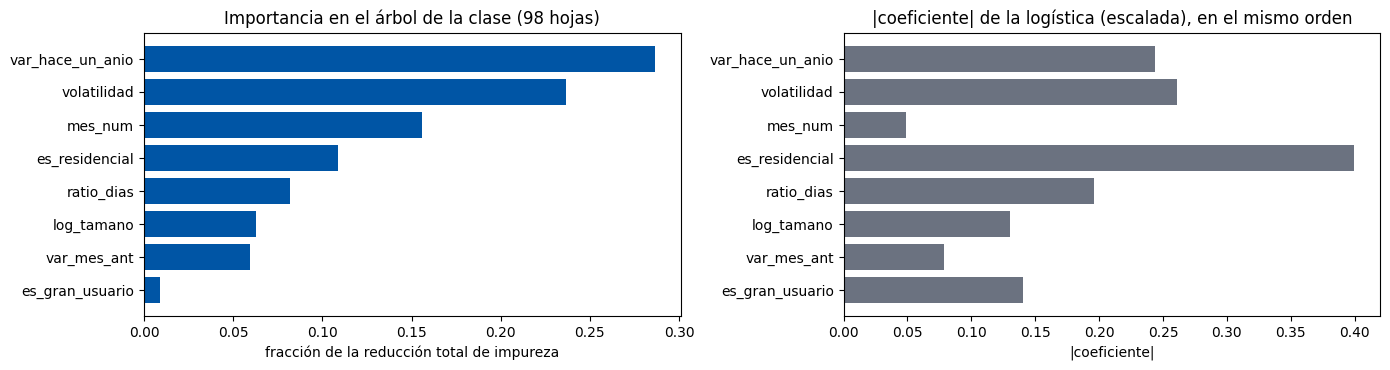

Columnas con importancia 0: ninguna
|--- volatilidad <= 0.15
|   |--- var_hace_un_anio <= -0.16
|   |   |--- var_hace_un_anio <= -0.20
|   |   |   |--- volatilidad <= 0.10
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- volatilidad >  0.10
|   |   |   |   |--- weights: [113.00, 87.00] class: 0
|   |   |--- var_hace_un_anio >  -0.20
|   |   |   |--- weights: [264.00, 86.00] class: 0
|   |--- var_hace_un_anio >  -0.16
|   |   |--- es_residencial <= 0.50
|   |   |   |--- var_hace_un_anio <= -0.05
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- var_hace_un_anio >  -0.05
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- es_residencial >  0.50
|   |   |   |--- var_hace_un_anio <= -0.07
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- var_hace_un_anio >  -0.07
|   |   |   |   |--- truncated branch of depth 5
|--- volatilidad >  0.15
|   |--- var_hace_un_anio <= -0.09
|   |   |--- var_mes_ant <= 0.65
|   |   |   |--- ratio_dias <

In [15]:
importancias = pd.Series(arbol.feature_importances_, index=PREDICTORAS).sort_values(ascending=False)
coef_log = pd.Series(np.abs(logistica[-1].coef_[0]), index=PREDICTORAS)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 3.8))
a.barh(importancias.index[::-1], importancias.values[::-1], color=AZUL); a.set_title(f"Importancia en el árbol de la clase ({arbol.get_n_leaves()} hojas)"); a.set_xlabel("fracción de la reducción total de impureza")
b.barh(importancias.index[::-1], coef_log[importancias.index[::-1]].values, color=GRIS); b.set_title("|coeficiente| de la logística (escalada), en el mismo orden"); b.set_xlabel("|coeficiente|")
plt.tight_layout(); plt.show()
print(f"Columnas con importancia 0: {list(importancias[importancias == 0].index) or 'ninguna'}")
print(export_text(arbol, feature_names=PREDICTORAS, show_weights=True, max_depth=3))
print(f"(impreso hasta profundidad 3 de {arbol.get_depth()}; «truncated branch» marca lo que sigue más abajo)")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El árbol y la logística no cuentan lo mismo. Para la logística lo que más pesaba era ser tarifa residencial; para el árbol, la variación del año pasado y la volatilidad, que usa en las primeras preguntas y en combinación. El caso más llamativo es <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">mes_num</code>: para la logística casi no pesaba, porque como número de 1 a 12 no tiene una tendencia lineal; el árbol lo usa cortándolo en grupos de meses (por ejemplo, «mes ≤ 5»), que es como realmente actúa. Ninguna de las dos lecturas es la verdad del fenómeno; son dos maneras de resumir la misma información.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.3 · Con desequilibrio, se sesga</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">class_weight="balanced"</code>: cada caída pesa ~3 y cada no-caída ~0,6 al calcular la impureza. Sube la exhaustividad a costa de la precisión, como en la clase 32, pero movido en el entrenamiento.</p></div>

In [16]:
NOMBRE_EQ = NOMBRE_ARBOL.replace("(validación)", "+ balanced")
equilibrado = registrar(NOMBRE_EQ, DecisionTreeClassifier(random_state=2026, class_weight="balanced", **params))
for k in [NOMBRE_ARBOL, NOMBRE_EQ]:
    r = resultados[k]; print(f"{k[:62]:62s} exhaustividad {r['exhaustividad']:.3f} · precisión {r['precisión']:.3f} · F1 {r['F1']:.3f} · AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f}")
print(f"Pesos: cada caída vale {len(y_ent) / (2 * y_ent.sum()):.2f}, cada no-caída {len(y_ent) / (2 * (len(y_ent) - y_ent.sum())):.2f} · raíz con pesos: {PREDICTORAS[equilibrado.tree_.feature[0]]} ≤ {equilibrado.tree_.threshold[0]:.3f} · hojas: {arbol.get_n_leaves()} → {equilibrado.get_n_leaves()}")

árbol, profundidad 10, mínimo 200 por hoja (validación)        exhaustividad 0.005 · precisión 0.571 · F1 0.010 · AUC 0.724 · log-loss 0.343
árbol, profundidad 10, mínimo 200 por hoja + balanced          exhaustividad 0.581 · precisión 0.259 · F1 0.358 · AUC 0.726 · log-loss 0.523
Pesos: cada caída vale 2.92, cada no-caída 0.60 · raíz con pesos: var_hace_un_anio ≤ -0.061 · hojas: 98 → 105


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.4 · Fronteras paralelas a los ejes</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La figura de la diapositiva con datos construidos para eso (400 puntos separados por una recta, y los mismos girados 45°), igual que en la cátedra.</p></div>

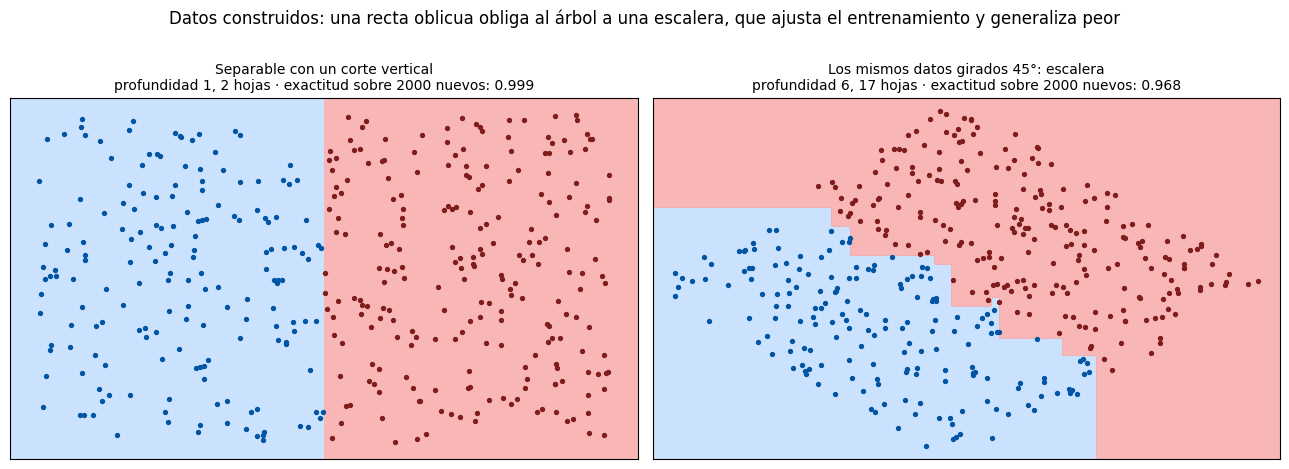

In [17]:
rng = np.random.default_rng(2026)
A = rng.uniform(0, 1, (400, 2)); y_rot = (A[:, 0] > 0.5).astype(int)
theta = np.pi / 4; R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]]); B = (A - 0.5) @ R.T + 0.5
A_nuevo = rng.uniform(0, 1, (2000, 2)); y_nuevo = (A_nuevo[:, 0] > 0.5).astype(int); B_nuevo = (A_nuevo - 0.5) @ R.T + 0.5
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, Xd, Xn, titulo in zip(ejes, [A, B], [A_nuevo, B_nuevo], ["Separable con un corte vertical", "Los mismos datos girados 45°: escalera"]):
    arbol_rot = DecisionTreeClassifier(random_state=2026).fit(Xd, y_rot)
    gx, gy = np.meshgrid(np.linspace(Xd[:, 0].min() - 0.05, Xd[:, 0].max() + 0.05, 300), np.linspace(Xd[:, 1].min() - 0.05, Xd[:, 1].max() + 0.05, 300))
    ax.contourf(gx, gy, arbol_rot.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), levels=[-0.5, 0.5, 1.5], colors=["#bfdbfe", "#f8a4a4"], alpha=0.8)
    ax.scatter(Xd[y_rot == 0, 0], Xd[y_rot == 0, 1], s=8, color=AZUL); ax.scatter(Xd[y_rot == 1, 0], Xd[y_rot == 1, 1], s=8, color="#7f1d1d")
    ax.set_title(f"{titulo}\nprofundidad {arbol_rot.get_depth()}, {arbol_rot.get_n_leaves()} hojas · exactitud sobre 2000 nuevos: {accuracy_score(y_nuevo, arbol_rot.predict(Xn)):.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Datos construidos: una recta oblicua obliga al árbol a una escalera, que ajusta el entrenamiento y generaliza peor", y=1.01)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.5 · Alta varianza: un cambio chico, otro árbol</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Tres experimentos. (1) Mismos datos, distinta semilla. (2) El 95 % de las filas al azar, diez veces: cuánto cambian la raíz, las hojas y las predicciones. (3) <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">max_features="sqrt"</code> (tres columnas al azar por nodo, como van a hacer los bosques).</p></div>

(1) Diez semillas · predicciones distintas de la semilla 0: sin freno [235, 250, 268, 263, 262, 235, 251, 266, 251] · con los frenos de la clase (probabilidades distintas) [0, 0, 0, 0, 0, 0, 0, 0, 0]
(2) Diez árboles con el 95 % · raíz: {'volatilidad': 6, 'var_hace_un_anio': 4} · hojas: [93, 97, 101, 96, 101, 94, 92, 93, 98, 97]
    segundo nivel (izquierda | derecha): {'var_hace_un_anio | var_hace_un_anio': 6, 'volatilidad | volatilidad': 4}
    desvío de p̂ entre los diez árboles, fila por fila: mediana 0.028, máximo 0.185 · AUC: [0.721, 0.726, 0.717, 0.716, 0.711, 0.722, 0.718, 0.72, 0.728, 0.718]


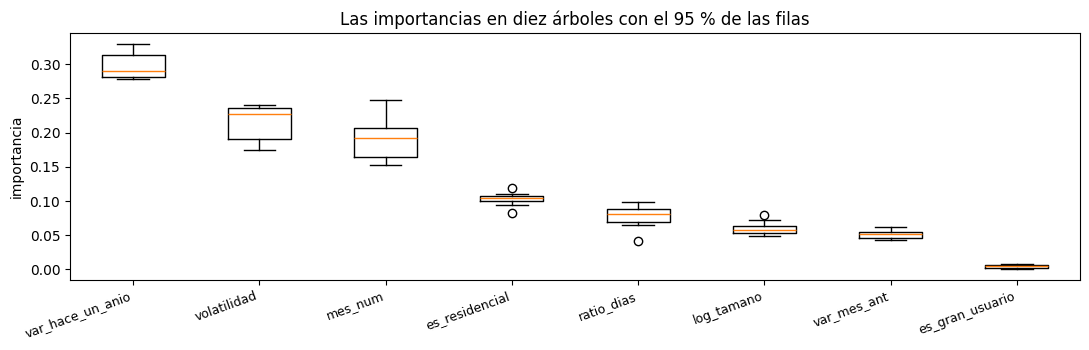

(3) max_features="sqrt", cinco semillas · raíz: ['es_residencial', 'es_residencial', 'var_hace_un_anio', 'log_tamano', 'volatilidad'] · AUC: [0.682, 0.737, 0.704, 0.72, 0.706]


In [18]:
semillas = range(10)
pred_base = DecisionTreeClassifier(random_state=0).fit(X_ent, y_ent).predict(X_pru)
sin_freno_semillas = [int((DecisionTreeClassifier(random_state=s).fit(X_ent, y_ent).predict(X_pru) != pred_base).sum()) for s in semillas]
p_base_f = DecisionTreeClassifier(random_state=0, **params).fit(X_ent, y_ent).predict_proba(X_pru)[:, 1]
frenado_semillas = [int((~np.isclose(DecisionTreeClassifier(random_state=s, **params).fit(X_ent, y_ent).predict_proba(X_pru)[:, 1], p_base_f)).sum()) for s in semillas]
print(f"(1) Diez semillas · predicciones distintas de la semilla 0: sin freno {sin_freno_semillas[1:]} · con los frenos de la clase (probabilidades distintas) {frenado_semillas[1:]}")
rng = np.random.default_rng(2026); submuestras = []
for s in semillas:
    idx = np.sort(rng.choice(len(X_ent), int(0.95 * len(X_ent)), replace=False))
    submuestras.append(DecisionTreeClassifier(random_state=2026, **params).fit(X_ent.iloc[idx], y_ent.iloc[idx]))
segundo = [f"{PREDICTORAS[m.tree_.feature[m.tree_.children_left[0]]]} | {PREDICTORAS[m.tree_.feature[m.tree_.children_right[0]]]}" for m in submuestras]
prob_sub = np.array([m.predict_proba(X_pru)[:, 1] for m in submuestras])
print(f"(2) Diez árboles con el 95 % · raíz: {pd.Series([PREDICTORAS[m.tree_.feature[0]] for m in submuestras]).value_counts().to_dict()} · hojas: {[int(m.get_n_leaves()) for m in submuestras]}")
print(f"    segundo nivel (izquierda | derecha): {pd.Series(segundo).value_counts().to_dict()}")
print(f"    desvío de p̂ entre los diez árboles, fila por fila: mediana {np.median(prob_sub.std(axis=0)):.3f}, máximo {prob_sub.std(axis=0).max():.3f} · AUC: {[round(roc_auc_score(y_pru, p), 3) for p in prob_sub]}")
imp = pd.DataFrame([m.feature_importances_ for m in submuestras], columns=PREDICTORAS)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.boxplot([imp[c_] for c_ in importancias.index], tick_labels=importancias.index); ax.set_ylabel("importancia"); plt.setp(ax.get_xticklabels(), rotation=20, ha="right", fontsize=9)
ax.set_title("Las importancias en diez árboles con el 95 % de las filas")
plt.tight_layout(); plt.show()
raices = [PREDICTORAS[DecisionTreeClassifier(random_state=s, max_features="sqrt", **params).fit(X_ent, y_ent).tree_.feature[0]] for s in range(5)]
aucs = [round(roc_auc_score(y_pru, DecisionTreeClassifier(random_state=s, max_features="sqrt", **params).fit(X_ent, y_ent).predict_proba(X_pru)[:, 1]), 3) for s in range(5)]
print(f"(3) max_features=\"sqrt\", cinco semillas · raíz: {raices} · AUC: {aucs}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sin freno, cambiar solo la semilla cambia cientos de predicciones. Con los frenos de la clase el árbol es mucho más estable, pero sacar un 5 % de las filas cambia las hojas, las importancias y las probabilidades de cada fila. Con tres columnas al azar por nodo, la raíz cambia de corrida a corrida. Esa varianza es justamente lo que se ataca promediando muchos árboles distintos: es lo que sigue en la materia.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">E · El comparativo: cuál resultó mejor, y cómo se elige</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La matriz, el AUC y la decisión</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Todo lo registrado: las referencias y las variantes del árbol. Verde es mejor en cada columna.</p></div>

In [19]:
METRICAS = ["exactitud", "precisión", "exhaustividad", "F1", "AUC", "log-loss", "ajuste (ms)", "predicción (ms)"]
matriz = pd.DataFrame({k: {m: v[m] for m in METRICAS} for k, v in resultados.items()}).T.astype(float)
(matriz.style.format({m: "{:.3f}" for m in METRICAS[:6]}).format({"ajuste (ms)": "{:.1f}", "predicción (ms)": "{:.1f}"})
       .background_gradient(subset=["exactitud", "precisión", "exhaustividad", "F1", "AUC"], cmap="RdYlGn")
       .background_gradient(subset=["log-loss", "ajuste (ms)", "predicción (ms)"], cmap="RdYlGn_r"))

,exactitud,precisión,exhaustividad,F1,AUC,log-loss,ajuste (ms),predicción (ms)
línea de base (mayoritaria),0.873119,0.000000,0.000000,0.000000,0.500000,4.573242,3.8,0.8
regresión logística (clase 32),0.873454,0.555556,0.013175,0.025740,0.662507,0.364760,59.9,2.9
"k vecinos, k=101 (clase 34)",0.873955,0.600000,0.019763,0.038265,0.741016,0.343047,95.1,1051.5
"árbol, profundidad 2",0.873119,0.000000,0.000000,0.000000,0.687534,0.355424,51.2,2.1
árbol sin freno,0.794717,0.239734,0.284585,0.260241,0.576717,7.399132,265.0,3.8
"árbol, profundidad 10, mínimo 200 por hoja (validación)",0.873287,0.571429,0.005270,0.010444,0.724198,0.343223,153.6,3.3
"árbol podado, α = 1.15e-04",0.867268,0.410256,0.105402,0.167715,0.711291,0.366362,313.8,2.1
"árbol, profundidad 10, mínimo 200 por hoja + balanced",0.736041,0.259107,0.581028,0.358391,0.726079,0.522607,162.2,2.3


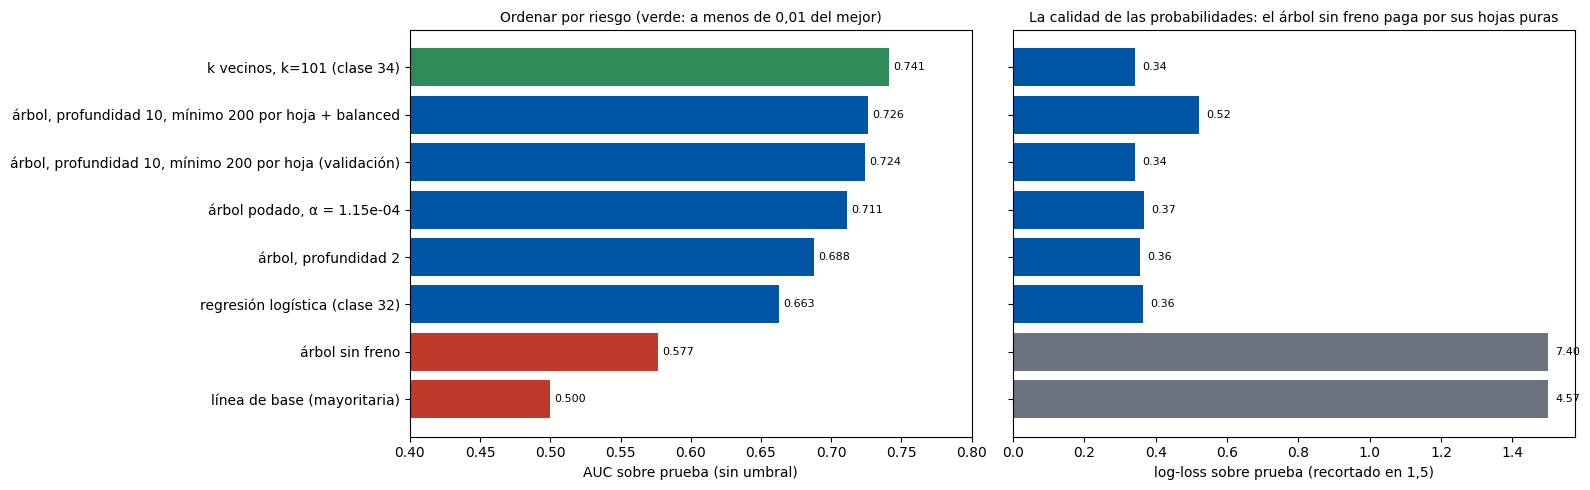

In [20]:
fig, (a, b) = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
orden = matriz.sort_values("AUC", ascending=False)
mejor_auc = orden["AUC"].max()
a.barh(orden.index, orden["AUC"], color=[VERDE if v >= mejor_auc - 0.01 else (ROJO if v < 0.6 else AZUL) for v in orden["AUC"]]); a.invert_yaxis(); a.set_xlim(0.4, 0.8)
for k, v in enumerate(orden["AUC"]): a.text(v + 0.003, k, f"{v:.3f}", va="center", fontsize=8)
a.set_xlabel("AUC sobre prueba (sin umbral)"); a.set_title("Ordenar por riesgo (verde: a menos de 0,01 del mejor)", fontsize=10)
b.barh(orden.index, orden["log-loss"].clip(upper=1.5), color=[AZUL if v < 1 else GRIS for v in orden["log-loss"]])
for k, v in enumerate(orden["log-loss"]): b.text(min(v, 1.5) + 0.02, k, f"{v:.2f}", va="center", fontsize=8)
b.set_xlabel("log-loss sobre prueba (recortado en 1,5)"); b.set_title("La calidad de las probabilidades: el árbol sin freno paga por sus hojas puras", fontsize=10)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La elección</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">El orden</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Igual que en la cátedra: por AUC, el árbol de la cuadrícula queda arriba de la logística y abajo de los vecinos. Con dos preguntas ya le ganaba a la logística, porque capta la interacción entre volatilidad y lo que pasó el año pasado.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que tiene el árbol</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Se lee entero, no necesita escalar, acepta los faltantes sin imputar y predice al instante. Cada predicción es una cadena de preguntas que se puede mostrar y discutir.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo frágil</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La varianza (D.5) y las fronteras paralelas a los ejes. Y para los MWh, como los vecinos, no extrapola.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cuándo elegirlo</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Si la explicación vale más que unas centésimas de AUC, es el modelo. Si no, es el punto de partida de los bosques: muchos árboles promediados, que bajan esa varianza.</td></tr></table></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">F · Usarlo: cada fila, con su cadena de preguntas</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Dos agentes nuevos, y por dónde pasan</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Los dos agentes inventados de las clases anteriores por el árbol de la clase: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">decision_path</code> dice qué nodos recorrió cada fila, y con eso se escribe la cadena de preguntas. Con un faltante, dice de qué lado lo mandó el árbol.</p></div>

In [21]:
def legible(col, v):
    if pd.isna(v): return "faltante"
    if col == "log_tamano": return f"{v:.2f} (≈ {10 ** v:,.0f} MWh)".replace(",", ".")
    if col in ("var_mes_ant", "var_hace_un_anio", "volatilidad"): return f"{v * 100:+.0f} %" if col != "volatilidad" else f"{v * 100:.0f} %"
    if col == "ratio_dias": return f"{v:.3f}"
    return f"{v:.0f}"
def umbral_legible(col, u):
    if col == "log_tamano": return f"{u:.2f} (≈ {10 ** u:,.0f} MWh)".replace(",", ".")
    if col in ("var_mes_ant", "var_hace_un_anio", "volatilidad"): return f"{u * 100:+.1f} %" if col != "volatilidad" else f"{u * 100:.1f} %"
    return f"{u:.3g}"
def camino(modelo, fila):
    """La cadena de preguntas que una fila recorre, de la raíz a la hoja, y lo que hay en la hoja."""
    t = modelo.tree_; nodos = modelo.decision_path(fila).indices; pasos = []
    for nodo in nodos[:-1]:
        col, umbral, valor = PREDICTORAS[t.feature[nodo]], t.threshold[nodo], fila.iloc[0, t.feature[nodo]]
        if pd.isna(valor):
            pasos.append(f"{col} faltante → {'≤' if t.missing_go_to_left[nodo] else '>'} {umbral_legible(col, umbral)} (por donde el árbol manda los faltantes)")
        else:
            pasos.append(f"{col} = {legible(col, valor)} {'≤' if valor <= umbral else '>'} {umbral_legible(col, umbral)}")
    hoja = nodos[-1]; cuentas = (t.value[hoja][0] * t.weighted_n_node_samples[hoja]).round().astype(int)
    return " → ".join(pasos), hoja, cuentas
nuevo = pd.DataFrame([
    {"ratio_dias": 31 / 28, "var_mes_ant": 0.02, "volatilidad": 0.02, "var_hace_un_anio": 0.08, "log_tamano": np.log10(80000), "mes_num": 3, "es_gran_usuario": 0, "es_residencial": 1},
    {"ratio_dias": 28 / 31, "var_mes_ant": 0.60, "volatilidad": 0.60, "var_hace_un_anio": np.nan, "log_tamano": np.log10(150), "mes_num": 2, "es_gran_usuario": 1, "es_residencial": 0},
], index=["distribuidora grande · marzo", "gran usuario chico · febrero"])
nuevo["p̂ árbol"] = arbol.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["p̂ vecinos"] = vecinos.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["p̂ logística"] = logistica.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
display(nuevo)
for k in range(2):
    pasos, hoja, cuentas = camino(arbol, nuevo[PREDICTORAS].iloc[[k]])
    print(f"{nuevo.index[k]}: {pasos} → hoja {hoja}: {cuentas[1]} de {cuentas.sum()} cayeron → p̂ = {cuentas[1] / cuentas.sum():.3f}\n")

,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,p̂ árbol,p̂ vecinos,p̂ logística
distribuidora grande · marzo,1.107143,0.02,0.02,0.08,4.903090,3,0,1,0.072,0.149,0.110
gran usuario chico · febrero,0.903226,0.60,0.60,NaN,2.176091,2,1,0,0.289,0.277,0.243


distribuidora grande · marzo: volatilidad = 2 % ≤ 15.3 % → var_hace_un_anio = +8 % > -15.5 % → es_residencial = 1 > 0.5 → var_hace_un_anio = +8 % > -6.8 % → log_tamano = 4.90 (≈ 80.000 MWh) > 1.81 (≈ 64 MWh) → ratio_dias = 1.107 > 0.984 → log_tamano = 4.90 (≈ 80.000 MWh) > 3.83 (≈ 6.757 MWh) → hoja 109: 21 de 291 cayeron → p̂ = 0.072

gran usuario chico · febrero: volatilidad = 60 % > 15.3 % → var_hace_un_anio faltante → ≤ -8.7 % (por donde el árbol manda los faltantes) → var_mes_ant = +60 % ≤ +65.2 % → ratio_dias = 0.903 ≤ 0.984 → var_hace_un_anio faltante → > -20.5 % (por donde el árbol manda los faltantes) → es_residencial = 0 ≤ 0.5 → log_tamano = 2.18 (≈ 150 MWh) ≤ 2.77 (≈ 586 MWh) → hoja 117: 100 de 346 cayeron → p̂ = 0.289



<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Diez filas de prueba, con su hoja</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Diez filas que cubren el rango de p̂ del árbol: la hoja, cuántas filas de entrenamiento había y cuántas cayeron, cuántas preguntas, y lo que dicen los vecinos y la logística. Varias filas caen en la misma hoja y reciben la misma p̂: «a escalones».</p></div>

In [22]:
prob_arbol = arbol.predict_proba(X_pru)[:, 1]
objetivos = np.linspace(prob_arbol.min(), prob_arbol.max(), 10)
elegidos, usados = [], set()
for objetivo in objetivos:
    for candidato in np.argsort(np.abs(prob_arbol - objetivo), kind="stable"):
        if candidato not in usados: elegidos.append(candidato); usados.add(candidato); break
elegidos = np.array(elegidos)
explicado = X_pru.iloc[elegidos].copy(); detalles = []
for j in elegidos:
    pasos, hoja, cuentas = camino(arbol, X_pru.iloc[[j]])
    detalles.append({"hoja": hoja, "preguntas": pasos.count("→") + 1, "en la hoja": int(cuentas.sum()), "cayeron": int(cuentas[1])})
explicado = pd.concat([explicado, pd.DataFrame(detalles, index=explicado.index)], axis=1)
explicado.insert(0, "serie", datos.loc[explicado.index, "serie"].str.slice(0, 28).values)
explicado["p̂ árbol"] = prob_arbol[elegidos].round(3)
explicado["p̂ vecinos"] = vecinos.predict_proba(X_pru.iloc[elegidos])[:, 1].round(3)
explicado["p̂ logística"] = logistica.predict_proba(X_pru.iloc[elegidos])[:, 1].round(3)
explicado["real"] = y_pru.iloc[elegidos].values
explicado.index.name = "fila"
(explicado.style.format(precision=2)
    .background_gradient(subset=["p̂ árbol", "p̂ vecinos", "p̂ logística"], cmap="RdYlGn_r", vmin=0, vmax=0.6)
    .set_caption("Diez filas de prueba que cubren el rango de p̂ del árbol: la hoja, cuántas filas había y cuántas cayeron, y lo que dicen los otros dos modelos"))

,serie,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,hoja,preguntas,en la hoja,cayeron,p̂ árbol,p̂ vecinos,p̂ logística,real
fila,,,,,,,,,,,,,,,,,
31500,C16OCTUW | RESIDENCIAL,1.03,0.03,0.03,0.00,3.49,7,0,1,108,8,297,3,0.01,0.01,0.16,0
36672,AIRLVCSY | GUMAS/AUTOGENERAD,0.94,-0.02,0.02,0.28,3.85,2,1,0,27,8,342,24,0.07,0.15,0.12,0
31612,CLUJAN1W | TARIFA USUARIO NO,1.03,0.00,0.00,-0.11,3.61,7,0,0,21,7,242,32,0.13,0.04,0.09,0
31437,ALPAVACY | GUMAS/AUTOGENERAD,1.03,0.02,0.02,-0.13,2.38,7,1,0,20,7,266,51,0.19,0.08,0.13,0
33237,CTRLAU1W | TARIFA USUARIO NO,0.97,-0.16,0.16,-0.15,3.75,9,0,0,124,8,326,82,0.25,0.15,0.12,0
32450,CRAWSOUW | TARIFA USUARIO NO,1.00,0.81,0.81,-0.11,2.99,8,0,0,172,5,354,117,0.33,0.21,0.15,1
31459,ARCOLPTA | GUMAS/AUTOGENERAD,1.03,-0.09,0.09,-0.42,2.49,7,1,0,6,5,274,103,0.38,0.31,0.17,0
31446,APARSMSY | GUMAS/AUTOGENERAD,1.03,-0.12,0.12,-0.41,2.80,7,1,0,7,4,200,87,0.43,0.30,0.17,0
33040,CBARKE3W | TARIFA BASE ELECT,0.97,0.34,0.34,-0.16,0.64,9,0,1,138,9,373,185,0.50,0.33,0.32,1


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Los mismos diez, con su cadena de preguntas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Lo que se le diría a quien planifica: las preguntas que el árbol hizo, con los valores de la fila, y qué pasó con las filas de entrenamiento que respondieron igual. No «aporta +0,26», sino «se movió más de 15 % el mes pasado y el año pasado bajó en esta misma transición, como otras 300 filas de las que cayó un tercio».</p></div>

In [23]:
for fila_id, j in zip(explicado.index, elegidos):
    pasos, hoja, cuentas = camino(arbol, X_pru.iloc[[j]])
    real = "cayó" if y_pru.iloc[j] == 1 else "no cayó"
    print(f"{explicado.loc[fila_id, 'serie']} ({real}) · p̂ {prob_arbol[j]:.3f} (vecinos {explicado.loc[fila_id, 'p̂ vecinos']:.2f}, logística {explicado.loc[fila_id, 'p̂ logística']:.2f}):\n    {pasos}\n    → de las {cuentas.sum()} filas de entrenamiento que respondieron igual, {cuentas[1]} cayeron.\n")

C16OCTUW | RESIDENCIAL (no cayó) · p̂ 0.010 (vecinos 0.01, logística 0.16):
    volatilidad = 3 % ≤ 15.3 % → var_hace_un_anio = +0 % > -15.5 % → es_residencial = 1 > 0.5 → var_hace_un_anio = +0 % > -6.8 % → log_tamano = 3.49 (≈ 3.125 MWh) > 1.81 (≈ 64 MWh) → ratio_dias = 1.033 > 0.984 → log_tamano = 3.49 (≈ 3.125 MWh) ≤ 3.83 (≈ 6.757 MWh) → log_tamano = 3.49 (≈ 3.125 MWh) > 2.92 (≈ 838 MWh)
    → de las 297 filas de entrenamiento que respondieron igual, 3 cayeron.

AIRLVCSY | GUMAS/AUTOGENERAD (no cayó) · p̂ 0.070 (vecinos 0.15, logística 0.12):
    volatilidad = 2 % ≤ 15.3 % → var_hace_un_anio = +28 % > -15.5 % → es_residencial = 0 ≤ 0.5 → var_hace_un_anio = +28 % > -5.2 % → ratio_dias = 0.935 ≤ 0.984 → mes_num = 2 ≤ 5 → var_hace_un_anio = +28 % ≤ +63.8 % → log_tamano = 3.85 (≈ 7.024 MWh) > 3.32 (≈ 2.110 MWh)
    → de las 342 filas de entrenamiento que respondieron igual, 24 cayeron.

CLUJAN1W | TARIFA USUARIO NO (no cayó) · p̂ 0.132 (vecinos 0.04, logística 0.09):
    volatilidad = 0

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La misma predicción, en una aplicación</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se guarda el árbol de la clase con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">joblib</code>: un <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">DecisionTreeClassifier</code> solo, sin flujo, porque no necesita imputar ni escalar. La app lo carga junto con los modelos de las clases 32 y 34 (si están en la carpeta) y muestra las cuatro probabilidades; en la pestaña del árbol, la cadena de preguntas. Su probabilidad se mueve en escalones: solo cambia cuando un valor cruza el umbral de alguna pregunta.</p></div>

In [24]:
import joblib

joblib.dump(arbol, "modelo_cammesa_35.joblib")
cargado = joblib.load("modelo_cammesa_35.joblib")
print("Modelo guardado: modelo_cammesa_35.joblib")
print("Mismas probabilidades tras guardar y cargar:", np.allclose(cargado.predict_proba(X_pru), arbol.predict_proba(X_pru)),
      f"· {cargado.get_n_leaves()} hojas, profundidad {cargado.get_depth()} · {Path('modelo_cammesa_35.joblib').stat().st_size / 1024:,.0f} KB")

Modelo guardado: modelo_cammesa_35.joblib
Mismas probabilidades tras guardar y cargar: True · 98 hojas, profundidad 10 · 17 KB


In [25]:
%%writefile app_cammesa_35.py
# Clase 35 sobre CAMMESA · árbol de decisión, contra los modelos de las clases 32 y 34 · aplicación Streamlit
# Para abrirla, desde la carpeta del cuaderno:  streamlit run app_cammesa_35.py
import calendar
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

PREDICTORAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num", "es_gran_usuario", "es_residencial"]
AZUL, ROJO = "#0055a5", "#c0392b"
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

st.set_page_config(page_title="¿Va a caer fuerte la demanda?", layout="centered")
st.title("¿La demanda de este agente va a caer fuerte?")
st.caption("Regresión logística (clase 32), k vecinos y Bayes ingenuo (clase 34) y árbol de decisión (clase 35), sobre demanda-ltimos-aos.csv (CAMMESA).")

# ---------- 1 · Los modelos guardados por los cuadernos ----------
MODELOS = {
    "regresión logística": ("modelo_cammesa_32.joblib", "Clase_32_regresion_logistica_y_softmax_CAMMESA.ipynb"),
    "k vecinos": ("modelo_cammesa_34_knn.joblib", "Clase_34_k_vecinos_y_Bayes_ingenuo_CAMMESA.ipynb"),
    "Bayes ingenuo": ("modelo_cammesa_34_bayes.joblib", "Clase_34_k_vecinos_y_Bayes_ingenuo_CAMMESA.ipynb"),
    "árbol de decisión": ("modelo_cammesa_35.joblib", "Clase_35_arboles_de_decision_CAMMESA.ipynb"),
}
PROPIOS = ["árbol de decisión"]

@st.cache_resource
def cargar(archivo):
    return joblib.load(archivo)

modelos = {}
for nombre, (archivo, cuaderno) in MODELOS.items():
    if Path(archivo).exists():
        modelos[nombre] = cargar(archivo)
    elif nombre in PROPIOS:
        st.error(f"Falta {archivo}. Ejecutar antes el cuaderno {cuaderno}, que lo genera."); st.stop()
    else:
        st.warning(f"Falta {archivo} (lo genera {cuaderno}): la comparación se muestra sin {nombre}.")
config = json.loads(Path("umbral_cammesa_32.json").read_text(encoding="utf-8")) if Path("umbral_cammesa_32.json").exists() else {"umbral": 0.15}

# ---------- 2 · La historia del agente ----------
st.subheader("Historia del agente")
c1, c2 = st.columns(2)
lag1 = c1.number_input("Demanda del mes anterior (MWh)", 1.0, 1_600_000.0, 5_000.0, step=100.0)
lag2 = c1.number_input("Demanda de hace dos meses (MWh)", 0.0, 1_600_000.0, 4_800.0, step=100.0)
conoce_anio = c1.checkbox("Conozco el año pasado", value=True)
lag12 = c1.number_input("Hace un año: el mismo mes (MWh)", 0.0, 1_600_000.0, 5_200.0, step=100.0, disabled=not conoce_anio)
lag13 = c1.number_input("Hace un año: el mes anterior (MWh)", 0.0, 1_600_000.0, 5_000.0, step=100.0, disabled=not conoce_anio)
anio = c2.number_input("Año", 2017, 2030, 2020)
mes = MESES.index(c2.selectbox("Mes a predecir", MESES, index=1)) + 1
tipo = c2.radio("Tipo de agente", ["Distribuidor · residencial", "Distribuidor · no residencial", "Gran usuario"])
umbral = c2.slider("Umbral de decisión", 0.05, 0.60, float(config["umbral"]), step=0.01)

anio_ant, mes_ant = (anio - 1, 12) if mes == 1 else (anio, mes - 1)
var_mes_ant = float(np.clip(lag1 / lag2 - 1, -1, 3)) if lag2 > 0 else np.nan
var_anio = float(np.clip(lag12 / lag13 - 1, -1, 3)) if conoce_anio and lag13 > 0 else np.nan
fila = pd.DataFrame([{"ratio_dias": calendar.monthrange(anio, mes)[1] / calendar.monthrange(anio_ant, mes_ant)[1],
                      "var_mes_ant": var_mes_ant, "volatilidad": abs(var_mes_ant) if not np.isnan(var_mes_ant) else np.nan,
                      "var_hace_un_anio": var_anio, "log_tamano": np.log10(lag1), "mes_num": mes,
                      "es_gran_usuario": int(tipo == "Gran usuario"), "es_residencial": int(tipo == "Distribuidor · residencial")}])[PREDICTORAS]

# ---------- 3 · Probabilidad y decisión de cada modelo ----------
probs = {nombre: float(m.predict_proba(fila)[0, 1]) for nombre, m in modelos.items()}
st.subheader("Predicción")
for col, (nombre, p) in zip(st.columns(len(probs)), probs.items()):
    col.metric(nombre, f"{p * 100:.1f} %".replace(".", ","))
    col.markdown(f":{'red' if p >= umbral else 'blue'}[**{'alarma' if p >= umbral else 'sin alarma'}**]")
fig, ax = plt.subplots(figsize=(8, 0.6 + 0.55 * len(probs)))
ax.barh(list(probs), list(probs.values()), color=[ROJO if p >= umbral else AZUL for p in probs.values()])
ax.axvline(umbral, color="black", ls="--", lw=1.5, label=f"umbral = {umbral:.2f}")
for k, p in enumerate(probs.values()): ax.text(min(p + 0.01, 0.9), k, f"{p:.3f}", va="center")
ax.set_xlim(0, 1); ax.set_xlabel("p̂(cae fuerte)"); ax.invert_yaxis(); ax.legend(loc="lower right")
plt.tight_layout(); st.pyplot(fig)

# ---------- 4 · Por qué ----------
st.subheader("Por qué")
pestanas = dict(zip(modelos, st.tabs(list(modelos))))
with pestanas["árbol de decisión"]:
    arbol = modelos["árbol de decisión"]; t = arbol.tree_
    nodos = arbol.decision_path(fila).indices
    for nodo in nodos[:-1]:
        j = t.feature[nodo]; col, u, v = PREDICTORAS[j], t.threshold[nodo], fila.iloc[0, j]
        if pd.isna(v):
            st.write(f"• **{col}** falta → el árbol lo manda por {'≤' if t.missing_go_to_left[nodo] else '>'} {u:.3g}")
        else:
            st.write(f"• **{col}** = {v:.3g} {'≤' if v <= u else '>'} {u:.3g}")
    hoja = nodos[-1]; cuentas = (t.value[hoja][0] * t.weighted_n_node_samples[hoja]).round().astype(int)
    st.write(f"→ **hoja {hoja}**: de las {cuentas.sum()} filas de entrenamiento que respondieron igual, **{cuentas[1]}** cayeron: p̂ = {cuentas[1] / cuentas.sum():.3f}.")
if "k vecinos" in modelos:
    with pestanas["k vecinos"]:
        m = modelos["k vecinos"]; knn = m[-1]
        dist, pos = knn.kneighbors(m[:-1].transform(fila)); votos = knn._y[pos[0]]
        st.write(f"De sus **{knn.n_neighbors}** vecinos más parecidos, **{int(votos.sum())}** cayeron fuerte: p̂ = {votos.mean():.3f}.")
if "Bayes ingenuo" in modelos:
    with pestanas["Bayes ingenuo"]:
        m = modelos["Bayes ingenuo"]; nb = m[-1]; x = m[:-1].transform(fila)[0]
        def logpdf(v, mu, var): return -0.5 * np.log(2 * np.pi * var) - (v - mu) ** 2 / (2 * var)
        aportes = logpdf(x, nb.theta_[1], nb.var_[1]) - logpdf(x, nb.theta_[0], nb.var_[0])
        fig, ax = plt.subplots(figsize=(8, 3.4)); ax.barh(PREDICTORAS, aportes, color=[ROJO if v > 0 else AZUL for v in aportes]); ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
        ax.set_xlabel("aporte a las log-chances (rojo: hacia la caída)"); plt.tight_layout(); st.pyplot(fig)
if "regresión logística" in modelos:
    with pestanas["regresión logística"]:
        m = modelos["regresión logística"]; z = m[:-1].transform(fila)[0]; lg = m[-1]; aportes = lg.coef_[0] * z
        fig, ax = plt.subplots(figsize=(8, 3.4)); ax.barh(PREDICTORAS, aportes, color=[ROJO if v > 0 else AZUL for v in aportes]); ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
        ax.set_xlabel("aporte a las log-chances (rojo: hacia la caída)"); plt.tight_layout(); st.pyplot(fig)

with st.expander("Ver la fila que reciben los modelos"):
    st.dataframe(fila)

Writing app_cammesa_35.py


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Cómo abrirla</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit</code> en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">aa2026</code>: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit run app_cammesa_35.py</code> desde la carpeta del cuaderno. Para la comparación completa, correr antes los cuadernos 32 y 34 en la misma carpeta; si falta alguno, la app avisa y sigue con lo que haya. Si otra app sigue abierta, esta arranca en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">localhost:8502</code>.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Desde el cuaderno:</b> la celda siguiente la lanza sin consola; entrar a <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">http://localhost:8501</code> y, para cortarla, interrumpir el kernel (■).</p></div>

In [26]:
import sys
print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
!"{sys.executable}" -m streamlit run app_cammesa_35.py --server.headless true

Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).
^C


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">G · Qué quedó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Un árbol es una cadena de preguntas;</b> cada nodo guarda samples, value y gini. CART elige en cada nodo el corte que deja los dos lados más puros, ponderados por tamaño: con 31 000 filas, decenas de miles de umbrales en la raíz.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Con dos preguntas ya le gana a la logística,</b> porque capta una interacción (volátil el mes pasado <b>y</b> con baja el año pasado) que una suma no expresa. Y acepta los faltantes sin imputar.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Sin freno memoriza</b> mucho más que en la cátedra: miles de hojas de una fila, AUC por debajo de la logística y log-loss enorme. Con mínimo por hoja grande (elegido con validación temporal) o con poda, queda entre la logística y los vecinos: el mismo orden que en el ejemplo.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Para los MWh no sirve,</b> igual que los vecinos: una escalera no extrapola a los agentes gigantes. Ahí la recta sigue ganando.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Lo frágil:</b> fronteras paralelas a los ejes, sesgo con desequilibrio y varianza. Promediar muchos árboles para bajar esa varianza es lo que sigue.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Y usarlo:</b> la app compara los cuatro modelos de la unidad sobre la misma fila, y la explicación del árbol es la cadena de preguntas, que se puede leer en voz alta.</p></div>